# Entrega final · ¿Viene un día fuerte? Modelado predictivo para Salomé

Proyecto integrador · Analítica de Datos (IAD-2403)<br>
Profesor: Armando Gallardo Heredia · Ingeniería en Inteligencia Artificial, TecNM Campus Colima<br>
Equipo: Jarom Cortes Pérez · Carlos Antonio Vogel Romero<br>
Entrega: Entrega final (incluye los avances 1 y 2) · 30 de noviembre de 2026

Caso: Salomé, postrería casera de Villa de Álvarez, Colima, que vende por pedido en WhatsApp, Instagram y Facebook. Es el mismo negocio del proyecto DATA STARTUP de Cómputo en la Nube; aquí se trabaja la parte de modelado predictivo.

## 0. Preparación del entorno

Bibliotecas: pandas, NumPy, Matplotlib, Seaborn, SciPy y scikit-learn. La carpeta `datos/` trae el archivo crudo, el catálogo de precios y el calendario de días cerrados; `limpieza.py` es el módulo de limpieza del proyecto.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

import limpieza

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 11})
CAFE, ROSA, ARENA, GRIS = "#7a4a2e", "#d4768c", "#e3b77a", "#9a9a9a"
sns.set_palette([CAFE, ROSA, ARENA, "#5b8a72", GRIS])
DATOS = Path("datos")
FIG = Path("figuras"); FIG.mkdir(exist_ok=True)
SEMILLA = 2026

## 1. Definición del problema

Salomé hornea sola en su cocina. El cheesecake, que es su producto estrella, tiene que reposar una noche en el refrigerador, y el queso crema se compra antes. Por eso la cantidad de pasteles enteros que va a preparar para un día se decide dos días antes: el jueves decide el sábado.

Hoy lo decide a ojo. Cuando se queda corta tiene que rechazar pedidos (unos 500 pesos que se pierden cada vez); cuando prepara de más le sobra una base de cheesecake (unos 150 pesos en insumos que logra vender en rebanadas). En un día normal le alcanza con un pastel entero listo: en tres de cada cuatro días que abre entrega cero o uno. El problema es reconocer a tiempo los días que van a pedir dos o más.

Variable objetivo: `dia_fuerte`, que vale 1 si ese día se entregan 2 o más pasteles enteros y 0 si no. Es un problema de clasificación binaria.

Unidad de análisis: un día abierto de 2022 a octubre de 2026. Cada fila describe lo que Salomé sabe al cierre del día de la decisión, dos días antes: qué tiene ya apartado para esa fecha, cómo le fue la semana anterior y qué día del calendario es.

Valor práctico: si el modelo avisa el jueves que el sábado va a ser fuerte, Salomé compra queso crema y hornea una base más. Como rechazar un pedido cuesta más que una base sobrante, nos importa más no dejar pasar días fuertes (recall) que equivocarnos de vez en cuando hacia arriba (precisión). Esa asimetría define la métrica de selección en los avances siguientes.

Elegimos clasificación y no regresión porque la decisión de Salomé es de sí o no (¿hago una base extra?), y porque el número de pasteles por día es 0, 1 o 2 en nueve de cada diez días. Una regresión sobre esos conteos tan chicos daría un número con decimales que ella tendría que redondear a mano.

## 2. El conjunto de datos

Hay dos niveles:

1. Archivo de pedidos (`datos/pedidos_salome_2020_2026.csv`): un renglón por producto dentro de cada pedido, tal como se captura desde los chats. Va del 5 de febrero de 2020 al 31 de octubre de 2026.
2. Tabla de días (`datos/dias_salome.csv`), que construimos en la sección 5 a partir del archivo de pedidos ya limpio. Es la que alimenta los modelos.

El archivo llega hasta el 31 de octubre de 2026: es el historial de E0 y E1 (hasta el 24 de octubre) más la semana del 25 al 31 que entró por la API de ingesta en E2. Por eso tiene 8 renglones más que el que se describe en esos documentos.

Primero revisamos el archivo de pedidos tal como llega. Se lee todo como texto para no perder los errores de captura al convertir tipos.

In [2]:
crudo = pd.read_csv(DATOS / "pedidos_salome_2020_2026.csv", dtype=str)
print(f"{crudo.shape[0]:,} renglones y {crudo.shape[1]} columnas")
crudo.head()

2,627 renglones y 13 columnas


,pedido_id,cliente_id,fecha_pedido,hora_pedido,fecha_entrega,producto,categoria,unidades,precio_unitario,total,canal,entrega,metodo_pago
0,1001,C0001,2020-02-05,12:05,2020-02-06,Caja de brownies (6 pz),Galletas y brownies,1,120,120,Instagram,Domicilio,Efectivo
1,1002,C0002,2020-02-08,14:50,2020-02-14,Cheesecake frutos rojos entero,Pasteles enteros,1,380,380,WhatsApp,Domicilio,Efectivo
2,1003,C0003,2020-02-16,07:14,2020-02-16,Pay de limón entero,Pasteles enteros,1,260,260,Instagram,Recoge,Efectivo
3,1004,C0001,2020-02-17,18:22,2020-02-19,Caja de brownies (6 pz),Galletas y brownies,1,120,120,WhatsApp,Recoge,Transferencia
4,1004,C0001,2020-02-17,18:22,2020-02-19,Pay de limón entero,Pasteles enteros,1,260,260,WhatsApp,Recoge,Transferencia


In [3]:
diccionario = pd.DataFrame({
    "columna": crudo.columns,
    "tipo esperado": ["entero", "texto", "fecha", "hora", "fecha", "texto", "categoría", "entero",
                      "decimal (MXN)", "decimal (MXN)", "categoría", "categoría", "categoría"],
    "significado": ["Número de pedido (se repite si el pedido trae varios productos)", "Cliente anonimizado",
                    "Día en que llegó el mensaje", "Hora del mensaje", "Día en que se entrega (el día que se produce)",
                    "Producto del catálogo", "Pasteles enteros, Rebanadas, Galletas y brownies, Eventos o Temporada",
                    "Piezas de ese producto", "Precio de lista del día", "unidades × precio_unitario",
                    "WhatsApp, Instagram o Facebook", "Domicilio o Recoge", "Efectivo, Transferencia o Tarjeta"],
    "valores distintos": [crudo[c].nunique() for c in crudo.columns]})
diccionario

,columna,tipo esperado,significado,valores distintos
0,pedido_id,entero,Número de pedido (se repite si el pedido trae ...,1963
1,cliente_id,texto,Cliente anonimizado,711
2,fecha_pedido,fecha,Día en que llegó el mensaje,1272
3,hora_pedido,hora,Hora del mensaje,813
4,fecha_entrega,fecha,Día en que se entrega (el día que se produce),1130
5,producto,texto,Producto del catálogo,32
6,categoria,categoría,"Pasteles enteros, Rebanadas, Galletas y browni...",5
7,unidades,entero,Piezas de ese producto,16
8,precio_unitario,decimal (MXN),Precio de lista del día,40
9,total,decimal (MXN),unidades × precio_unitario,109


## 3. Calidad de los datos: nulos, formatos y atípicos

### 3.1 Valores nulos

In [4]:
nulos = crudo.isna().sum().to_frame("nulos")
nulos["% del total"] = (100 * nulos["nulos"] / len(crudo)).round(2)
nulos[nulos["nulos"] > 0]

,nulos,% del total
hora_pedido,13,0.49
unidades,7,0.27
precio_unitario,7,0.27


Son pocos (menos de 0.5% por columna) y cada uno tiene una explicación distinta, así que no conviene tratarlos igual:

- `hora_pedido` vacía: Salomé copió el pedido pero no la hora. No se puede reconstruir y no afecta la venta, así que se deja vacía.
- `unidades` vacía: se reconstruye con `total / precio_unitario` cuando el resultado es un entero.
- `precio_unitario` vacío: se toma el precio de lista vigente ese día del catálogo (`catalogo_precios.csv`).

Imputar con la media o la mediana aquí sería un error: tenemos reglas del propio negocio que dan el valor exacto.

### 3.2 Formatos inconsistentes y tipos de dato

In [5]:
catalogo = limpieza.cargar_catalogo(DATOS / "catalogo_precios.csv")
oficiales = set(catalogo["producto"])
fuera_catalogo = crudo.loc[~crudo["producto"].isin(oficiales), "producto"]
print(f"Nombres de producto que no están en el catálogo: {len(fuera_catalogo)}")
print(fuera_catalogo.value_counts().head(8).to_string())
print()
print("Canal tal como se capturó:", crudo["canal"].value_counts().to_dict())
unid_num = pd.to_numeric(crudo["unidades"], errors="coerce")
print("Unidades escritas como texto:", crudo.loc[unid_num.isna() & crudo["unidades"].notna(), "unidades"].unique()[:10])
fecha_iso = pd.to_datetime(crudo["fecha_pedido"], format="%Y-%m-%d", errors="coerce")
print("Fechas en formato DD/MM/AAAA:", int(fecha_iso.isna().sum()))
print("Renglones duplicados exactos:", int(crudo.duplicated().sum()))

Nombres de producto que no están en el catálogo: 40
producto
Cheesecake entero                  4
cheesecake frutos rojos entero     3
reb pay de limón                   3
Cheescake frutos rojos entero      3
Rebanada 3 leches                  3
Rebanada pay de limon              2
Pay de limon entero                2
Rebanada cheescake frutos rojos    2

Canal tal como se capturó: {'WhatsApp': 1753, 'Instagram': 751, 'Facebook': 97, 'Whats': 9, 'whatsapp': 4, 'WA': 4, 'IG': 3, 'insta': 3, 'face': 1, 'instagram': 1, 'FB': 1}
Unidades escritas como texto: <ArrowStringArray>
['3 pz', '1 pz', 'dos', 'uno', '4 pz', 'tres', '2 pz']
Length: 7, dtype: str
Fechas en formato DD/MM/AAAA: 26
Renglones duplicados exactos: 13


### 3.3 Atípicos

Revisamos las variables numéricas del renglón: `unidades` y `total`. Usamos dos criterios. El estadístico es el rango intercuartílico (fuera de Q1 − 1.5·IQR o Q3 + 1.5·IQR). El de negocio es el máximo creíble por renglón para una persona que hornea sola (por ejemplo, más de 3 pasteles enteros en un solo renglón es casi seguro un cero de más).

In [6]:
num = crudo.assign(unidades=unid_num, total=pd.to_numeric(crudo["total"], errors="coerce"),
                   precio_unitario=pd.to_numeric(crudo["precio_unitario"], errors="coerce"))

def fuera_iqr(s):
    q1, q3 = s.quantile([.25, .75])
    return (s < q1 - 1.5 * (q3 - q1)) | (s > q3 + 1.5 * (q3 - q1))

tope = num["categoria"].map(limpieza.MAXIMO_UNIDADES)
resumen = pd.DataFrame({
    "atípicos por IQR (global)": [int(fuera_iqr(num["unidades"].dropna()).sum()), int(fuera_iqr(num["total"].dropna()).sum())],
    "atípicos por IQR dentro de su categoría": [int(num.groupby("categoria")["unidades"].transform(fuera_iqr).sum()),
                                                int(num.groupby("categoria")["total"].transform(fuera_iqr).sum())],
    "imposibles para el negocio": [int((num["unidades"] > tope).sum()), int((num["total"] > 20000).sum())],
    "negativos": [int((num["unidades"] < 0).sum()), int((num["total"] < 0).sum())]}, index=["unidades", "total"])
resumen

,atípicos por IQR (global),atípicos por IQR dentro de su categoría,imposibles para el negocio,negativos
unidades,185,176,5,3
total,37,160,0,0


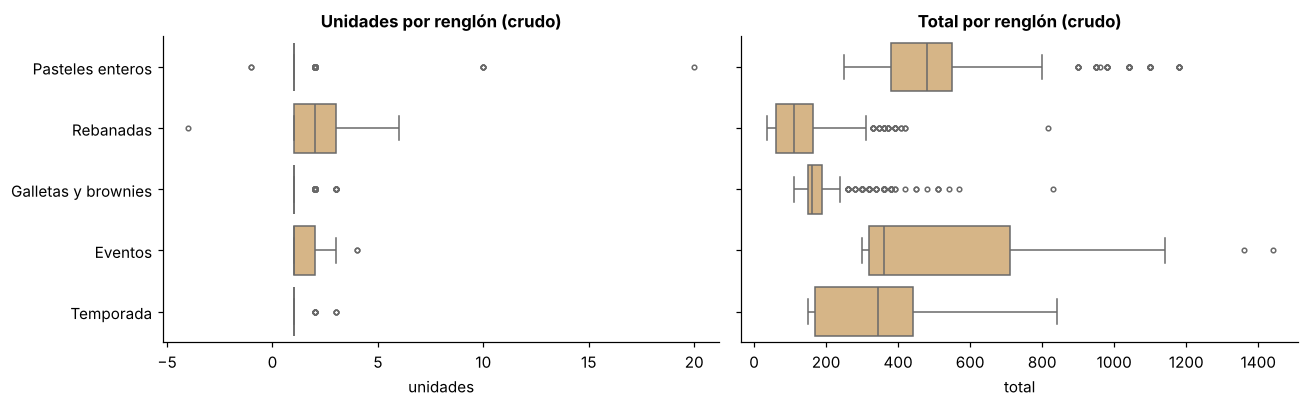

,pedido_id,producto,unidades,precio_unitario,total
110,1080,Pay de limón entero,10.00,260.00,260
657,1489,Flan napolitano entero,20.00,280.00,560
905,1677,Pay de limón entero,10.00,340.00,340
1141,1848,Cheesecake frutos rojos entero,10.00,490.00,490
2233,2668,Cheesecake frutos rojos entero,10.00,550.00,550


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
orden = ["Pasteles enteros", "Rebanadas", "Galletas y brownies", "Eventos", "Temporada"]
sns.boxplot(data=num, y="categoria", x="unidades", order=orden, ax=ax[0], color=ARENA, fliersize=3)
ax[0].set_title("Unidades por renglón (crudo)"); ax[0].set_ylabel("")
sns.boxplot(data=num, y="categoria", x="total", order=orden, ax=ax[1], color=ARENA, fliersize=3)
ax[1].set_title("Total por renglón (crudo)"); ax[1].set_ylabel(""); ax[1].set_yticklabels([])
plt.tight_layout(); plt.show()
num.loc[num["unidades"] > tope, ["pedido_id", "producto", "unidades", "precio_unitario", "total"]]

Los dos criterios no dicen lo mismo, y esa diferencia importa. El IQR marca hasta 185 renglones según la variable y el criterio, casi todos legítimos: 2 pasteles enteros en un pedido, 6 rebanadas para una oficina, una caja de galletas de 500 pesos o un pastel para evento de más de 1,000 pesos. Como en cada categoría la mayoría de los renglones trae 1 pieza, cualquier cosa distinta de 1 queda fuera del rango. Los que de verdad están mal son los 5 que rompen el tope del negocio: 10 o 20 pasteles enteros en un solo renglón, cuando el total corresponde a 1 o 2. Son errores de captura (un cero de más) y el total permite reconstruir el valor correcto. Lo mismo pasa con las 3 unidades negativas que se ven a la izquierda.

### 3.4 Errores lógicos

In [8]:
fp, _ = limpieza.a_fecha(crudo["fecha_pedido"])      # acepta AAAA-MM-DD y DD/MM/AAAA
fe, _ = limpieza.a_fecha(crudo["fecha_entrega"])
calc = num["unidades"] * num["precio_unitario"]
print("Entrega anterior al pedido:", int((fe < fp).sum()))
print("Total distinto de unidades × precio:", int((num["total"].notna() & calc.notna() & ~np.isclose(num["total"], calc)).sum()))
print("Unidades negativas:", int((num["unidades"] < 0).sum()))

Entrega anterior al pedido: 4
Total distinto de unidades × precio: 18
Unidades negativas: 3


Parte de los totales que no cuadran son los mismos renglones con unidades negativas o con un cero de más: al corregir las unidades, el total vuelve a cuadrar. Los que quedan después son totales mal tecleados.

### 3.5 Propuesta de tratamiento y aplicación

| Problema | Tratamiento propuesto | Por qué |
|---|---|---|
| Duplicados exactos | Quitar la copia | El mismo mensaje pegado dos veces |
| Nombre de producto, canal o entrega escrito distinto | Llevarlo al nombre oficial por similitud de texto y abreviaturas conocidas | Es el mismo producto; si no, se cuenta como otro |
| Unidades en texto ("dos", "2 pz") y fechas DD/MM/AAAA | Convertir al tipo correcto | Son datos buenos en otro formato |
| `precio_unitario` nulo | Precio de lista vigente ese día | El catálogo da el valor exacto |
| `unidades` nulas | `total / precio_unitario` | Cuadra con el resto del renglón |
| `hora_pedido` nula | Dejar vacía | No se puede saber y no afecta la venta |
| Unidades negativas | Valor absoluto | El signo es un error de tecleo |
| Entrega antes del pedido | Si es enero con el año viejo, sumar un año; si no, intercambiar | Son los dos errores que vimos en sus chats |
| Unidades por encima del tope | Reconstruir con `total / precio` | Un cero de más; el total sí está bien |
| Total que no cuadra | Recalcular `unidades × precio` | El total se tecleó mal |
| Atípicos por IQR que sí son posibles | Conservar | Son pedidos reales, grandes pero legítimos |
| Renglón sin forma de reconstruir | Apartar y reportar | No se inventan datos |

El módulo `limpieza.py` aplica exactamente estas reglas y reporta cuántos renglones tocó cada una.

In [9]:
limpio, reporte = limpieza.limpiar(crudo, catalogo)
print(f"{reporte.crudos:,} renglones crudos -> {reporte.limpios:,} limpios")
print(pd.Series(reporte.conteos).to_string())
print("Validación del archivo limpio:", limpieza.validar_limpio(limpio) or "sin problemas")
limpio.to_csv(DATOS / "pedidos_salome_limpio.csv", index=False, date_format="%Y-%m-%d")

2,627 renglones crudos -> 2,614 limpios
duplicados                           13
formato_producto                     38
formato_canal                        26
formato_entrega                       0
formato_pago                          0
producto_por_precio_y_categoria       1
unidades_texto                       10
fecha_formato                        26
precio_vacio                          7
unidades_vacias                       7
hora_vacia_sin_imputar               13
unidades_negativas                    3
fechas_invertidas                     4
unidades_atipicas                     5
total_inconsistente                  10
total_vacio                           0
precio_distinto_a_lista_reportado     0
irrecuperables_apartados              0
duplicados_tras_normalizar            0
Validación del archivo limpio: sin problemas


In [10]:
limpio = pd.read_csv(DATOS / "pedidos_salome_limpio.csv", parse_dates=["fecha_pedido", "fecha_entrega"])
pedidos = limpio.groupby("pedido_id").agg(fecha=("fecha_pedido", "first"), total=("total", "sum"), cliente=("cliente_id", "first"))
print(f"{len(limpio):,} renglones · {limpio['pedido_id'].nunique():,} pedidos · {limpio['cliente_id'].nunique()} clientes")
print(f"Del {limpio['fecha_pedido'].min():%d/%m/%Y} al {limpio['fecha_entrega'].max():%d/%m/%Y}")
pedidos.groupby(pedidos["fecha"].dt.year).agg(pedidos=("total", "size"), venta=("total", "sum"), ticket_mediano=("total", "median"))

2,614 renglones · 1,963 pedidos · 711 clientes
Del 05/02/2020 al 31/10/2026


,pedidos,venta,ticket_mediano
fecha,,,
2020,99,29645,300.00
2021,225,64828,264.00
2022,308,119080,361.00
2023,369,147588,340.00
2024,351,147514,360.00
2025,324,143372,380.00
2026,287,137270,400.00


Son cerca de 2,000 pedidos en casi siete años: de dos a tres por semana en 2020, cuando empezó con familia y amigos, y entre seis y siete por semana desde 2023. Es el tamaño que corresponde a una persona que hornea sola en su casa. 2020 y 2026 no son años completos.

## 4. Estadística descriptiva del archivo de pedidos

In [11]:
desc = limpio[["unidades", "precio_unitario", "total"]].describe().T
desc["mediana"] = limpio[["unidades", "precio_unitario", "total"]].median()
desc["CV"] = desc["std"] / desc["mean"]
desc["asimetría"] = limpio[["unidades", "precio_unitario", "total"]].skew()
desc[["count", "mean", "mediana", "std", "CV", "min", "25%", "75%", "max", "asimetría"]]

,count,mean,mediana,std,CV,min,25%,75%,max,asimetría
unidades,"2,614.00",1.56,1.00,1.04,0.66,1.00,1.00,2.00,6.00,2.34
precio_unitario,"2,614.00",249.96,170.00,193.52,0.77,35.00,62.00,450.00,590.00,0.39
total,"2,614.00",301.95,270.00,213.08,0.71,35.00,124.00,475.00,"1,440.00",1.10


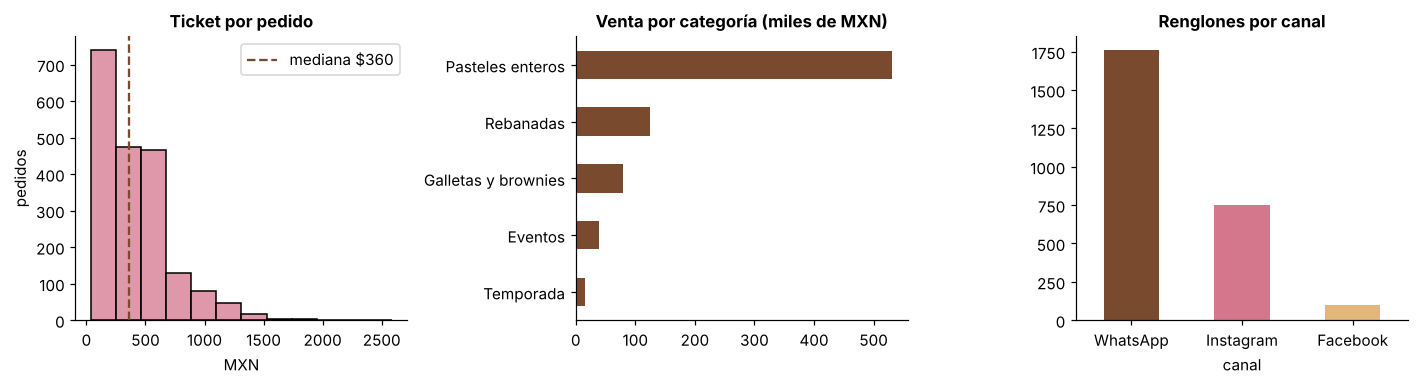

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
sns.histplot(pedidos["total"], bins=int(np.ceil(1 + np.log2(len(pedidos)))), ax=ax[0], color=ROSA)
ax[0].axvline(pedidos["total"].median(), color=CAFE, ls="--", label=f"mediana ${pedidos['total'].median():,.0f}")
ax[0].legend(); ax[0].set_title("Ticket por pedido"); ax[0].set_xlabel("MXN"); ax[0].set_ylabel("pedidos")
(limpio.groupby("categoria")["total"].sum().sort_values() / 1000).plot.barh(ax=ax[1], color=CAFE)
ax[1].set_title("Venta por categoría (miles de MXN)"); ax[1].set_ylabel("")
limpio["canal"].value_counts().plot.bar(ax=ax[2], color=[CAFE, ROSA, ARENA], rot=0)
ax[2].set_title("Renglones por canal")
plt.tight_layout(); plt.show()

El ticket está cargado a la derecha: la mitad de los pedidos son de 360 pesos o menos (rebanadas, cajas de galletas) y unos pocos pedidos grandes (eventos o varios pasteles juntos) pasan de 1,500 pesos. Los pasteles enteros son la categoría que más dinero deja, por eso el modelo se centra en ellos. WhatsApp concentra la mayoría de los pedidos.

## 5. Construcción de la tabla de días (la que usan los modelos)

Cada fila es un día abierto entre el 1 de enero de 2022 y el 31 de octubre de 2026. Empezamos en 2022 porque en 2020 y 2021 su horno solo le daba para dos pasteles enteros al día; con ese tope, "dos o más" significa otra cosa y mezclaría dos negocios distintos.

La regla para no hacer trampa: toda variable explicativa tiene que conocerse dos días antes, al cierre del día de la decisión. Por eso los apartados solo cuentan pedidos que llegaron con dos días o más de anticipación, y el promedio reciente se corta dos días antes. Los días cerrados (lunes, vacaciones, 25 de diciembre y 1 de enero) no entran, porque ese día no hay decisión que tomar.

| Variable | Tipo | Qué mide |
|---|---|---|
| `apartados_enteros` | numérica | Pasteles enteros ya apartados para ese día, dos días antes |
| `apartados_pedidos` | numérica | Pedidos de cualquier producto ya apartados para ese día |
| `apartados_monto` | numérica | Pesos ya apartados para ese día |
| `apartados_otros` | numérica | Piezas de otros productos (rebanadas, galletas) ya apartadas |
| `enteros_hace_7` | numérica | Pasteles enteros entregados el mismo día de la semana anterior (vacío si ese día estuvo cerrado) |
| `media_enteros_28` | numérica | Promedio de pasteles enteros por día abierto en los 28 días previos a la decisión |
| `dia_semana` | categórica | Martes a domingo (lunes solo cuando abrió por fecha especial) |
| `mes` | categórica | 1 a 12 |
| `tipo_fecha` | categórica | Normal, víspera o fecha fuerte (14 de febrero, 10 de mayo, Día del Padre, 24 y 31 de diciembre, Reyes) |
| `quincena` | binaria | 1 si cae en día de pago (14 al 16, fin de mes y día 1) |
| `enteros` | conteo | Pasteles enteros entregados ese día, contando también las docenas de cupcakes para eventos, las roscas y el pan de muerto, que ocupan el horno igual que un pastel (mismo criterio que E3). No es variable explicativa: de ahí sale el objetivo |
| `dia_fuerte` | objetivo | 1 si `enteros` ≥ 2 |

In [13]:
cierres = pd.to_datetime(pd.read_csv(DATOS / "calendario_cierres.csv")["fecha"])
ENTEROS = ["Pasteles enteros", "Eventos", "Temporada"]
FUERTES = {(2, 14), (5, 10), (12, 24), (12, 31), (1, 6)}
VISPERAS = {(2, 13), (5, 8), (5, 9), (12, 23), (12, 30), (1, 5)}
ESPECIALES = {(2, 13), (2, 14), (4, 30), (5, 8), (5, 9), (5, 10), (12, 23), (12, 24), (12, 30), (12, 31),
              (1, 2), (1, 3), (1, 4), (1, 5), (1, 6)}
DIAS = ["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"]
ANTICIPO = pd.Timedelta(days=2)

# Se arranca en noviembre de 2021 para que enero de 2022 ya tenga semana anterior y promedio de 28 días
idx = pd.date_range("2021-11-01", "2026-10-31", freq="D")
md_ = list(zip(idx.month, idx.day))
dia_padre = (idx.month == 6) & (idx.dayofweek == 6) & (idx.day >= 15) & (idx.day <= 21)
especial = np.array([m in ESPECIALES for m in md_]) | dia_padre
abierto = (((idx.dayofweek != 0) | especial)
           & ~(((idx.month == 12) & (idx.day == 25)) | ((idx.month == 1) & (idx.day == 1)))
           & ~idx.isin(cierres))

es_entero = limpio["categoria"].isin(ENTEROS)
enteros = limpio[es_entero].groupby("fecha_entrega")["unidades"].sum().reindex(idx, fill_value=0)
previos = limpio[limpio["fecha_pedido"] <= limpio["fecha_entrega"] - ANTICIPO]   # lo que ya estaba apartado
por_dia = lambda d, col, f: d.groupby("fecha_entrega")[col].agg(f).reindex(idx, fill_value=0)

dias = pd.DataFrame(index=pd.Index(idx, name="fecha"))
dias["apartados_enteros"] = por_dia(previos[previos["categoria"].isin(ENTEROS)], "unidades", "sum")
dias["apartados_pedidos"] = por_dia(previos, "pedido_id", "nunique")
dias["apartados_monto"] = por_dia(previos, "total", "sum")
dias["apartados_otros"] = por_dia(previos[~previos["categoria"].isin(ENTEROS)], "unidades", "sum")
enteros_abiertos = enteros.where(abierto)                     # un día cerrado no es demanda cero
dias["enteros_hace_7"] = enteros_abiertos.shift(7)
dias["media_enteros_28"] = enteros_abiertos.shift(2).rolling(28, min_periods=10).mean()
dias["dia_semana"] = [DIAS[d] for d in idx.dayofweek]
dias["mes"] = idx.month.astype(str)
dias["tipo_fecha"] = np.where(np.array([m in FUERTES for m in md_]) | dia_padre, "fecha fuerte",
                              np.where([m in VISPERAS for m in md_], "víspera", "normal"))
dias["quincena"] = (np.isin(idx.day, [1, 14, 15, 16]) | (idx.day >= idx.days_in_month - 1)).astype(int)
dias["enteros"] = enteros
dias["dia_fuerte"] = (enteros >= 2).astype(int)

dias = dias[(dias.index >= "2022-01-01") & abierto]
dias.to_csv(DATOS / "dias_salome.csv")
print(f"{len(dias):,} días abiertos · {dias.shape[1] - 2} variables explicativas · objetivo: dia_fuerte")
dias.head(8)

1,442 días abiertos · 10 variables explicativas · objetivo: dia_fuerte


,apartados_enteros,apartados_pedidos,apartados_monto,apartados_otros,enteros_hace_7,media_enteros_28,dia_semana,mes,tipo_fecha,quincena,enteros,dia_fuerte
fecha,,,,,,,,,,,,
2022-01-02,0,0,0,0,0.00,0.96,domingo,1,normal,0,0,0
2022-01-03,0,0,0,0,NaN,0.95,lunes,1,normal,0,0,0
2022-01-04,0,0,0,0,0.00,0.95,martes,1,normal,0,0,0
2022-01-05,0,0,0,0,0.00,0.91,miércoles,1,víspera,0,0,0
2022-01-06,1,1,400,0,1.00,0.91,jueves,1,fecha fuerte,0,1,0
2022-01-07,0,0,0,0,4.00,0.87,viernes,1,normal,0,0,0
2022-01-08,1,1,280,0,NaN,0.91,sábado,1,normal,0,1,0
2022-01-09,0,0,0,0,0.00,0.83,domingo,1,normal,0,0,0


In [14]:
NUMERICAS = ["apartados_enteros", "apartados_pedidos", "apartados_monto", "apartados_otros",
             "enteros_hace_7", "media_enteros_28"]
CATEGORICAS = ["dia_semana", "mes", "tipo_fecha"]
BINARIAS = ["quincena"]
dias.dtypes.to_frame("tipo").T

,apartados_enteros,apartados_pedidos,apartados_monto,apartados_otros,enteros_hace_7,media_enteros_28,dia_semana,mes,tipo_fecha,quincena,enteros,dia_fuerte
tipo,int64,int64,int64,int64,float64,float64,str,str,str,int64,int64,int64


## 6. Estadística descriptiva de la tabla de días

### 6.1 Variable objetivo

In [15]:
balance = dias["dia_fuerte"].value_counts().rename({0: "día normal (0)", 1: "día fuerte (1)"}).to_frame("días")
balance["%"] = (100 * balance["días"] / len(dias)).round(1)
display(balance)
print("Pasteles enteros por día:", dias["enteros"].value_counts().sort_index().to_dict())

,días,%
dia_fuerte,,
día normal (0),1123,77.90
día fuerte (1),319,22.10


Pasteles enteros por día: {0: 815, 1: 308, 2: 170, 3: 97, 4: 42, 5: 4, 6: 3, 7: 1, 8: 2}


Las clases están desbalanceadas: más o menos uno de cada cinco días es fuerte. Un modelo que dijera siempre "día normal" acertaría cerca de 78% de las veces y no serviría de nada, porque nunca avisaría. Por eso la exactitud (accuracy) sola no basta para comparar modelos; hay que ver precisión, recall y F1, y para la selección usaremos F2, que pesa más el recall.

### 6.2 Variables numéricas

In [16]:
d = dias[NUMERICAS + ["enteros"]]
tabla = d.describe().T
tabla["mediana"] = d.median()
tabla["IQR"] = tabla["75%"] - tabla["25%"]
tabla["CV"] = tabla["std"] / tabla["mean"]
tabla["asimetría"] = d.skew()
tabla["curtosis"] = d.kurt()
tabla["nulos"] = d.isna().sum()
tabla[["count", "nulos", "mean", "mediana", "std", "IQR", "CV", "min", "max", "asimetría", "curtosis"]]

,count,nulos,mean,mediana,std,IQR,CV,min,max,asimetría,curtosis
apartados_enteros,"1,442.00",0,0.46,0.00,0.93,1.00,2.03,0.00,8.00,2.79,10.92
apartados_pedidos,"1,442.00",0,0.36,0.00,0.67,1.00,1.88,0.00,5.00,2.17,5.54
apartados_monto,"1,442.00",0,226.82,0.00,462.03,360.00,2.04,0.00,"4,354.00",2.81,11.35
apartados_otros,"1,442.00",0,0.25,0.00,0.96,0.00,3.81,0.00,9.00,4.92,27.63
enteros_hace_7,"1,360.00",82,0.82,0.00,1.18,1.00,1.44,0.00,8.00,1.72,3.57
media_enteros_28,"1,442.00",0,0.80,0.76,0.26,0.33,0.33,0.24,1.96,0.82,1.22
enteros,"1,442.00",0,0.81,0.00,1.17,1.00,1.44,0.00,8.00,1.71,3.50


Lo que se lee en la tabla:

- Las cuatro variables de apartados tienen la mediana en 0 y la media arriba de la mediana, con asimetría positiva fuerte (entre 2.2 y 4.9). La mayoría de los días llega sin nada apartado dos días antes y unos cuantos llegan con mucho. No siguen una distribución normal; lo confirmamos con la prueba de Shapiro-Wilk abajo.
- `apartados_otros` tiene el coeficiente de variación más alto (3.8): casi siempre vale 0 y de vez en cuando llega a 8 o 9 piezas. `apartados_monto` va de 0 pesos a más de 4,000 pesos.
- `media_enteros_28` es la más estable (CV de 0.33): cambia despacio y resume el nivel del negocio en el último mes, entre 0.24 y 1.96 pasteles por día.
- `enteros_hace_7` es la única con nulos, en los días cuya semana anterior estuvo cerrada.

In [17]:
pd.DataFrame({c: stats.shapiro(dias[c].dropna().sample(500, random_state=SEMILLA)) for c in NUMERICAS},
             index=["estadístico W", "p"]).T

,estadístico W,p
apartados_enteros,0.54,0.00
apartados_pedidos,0.57,0.00
apartados_monto,0.55,0.00
apartados_otros,0.31,0.00
enteros_hace_7,0.71,0.00
media_enteros_28,0.96,0.00


Con p < 0.05 en todas, se rechaza normalidad. Esto pesa en la elección de modelos: Naive Bayes gaussiano supone variables normales dentro de cada clase, así que puede quedar en desventaja.

### 6.3 Variables categóricas

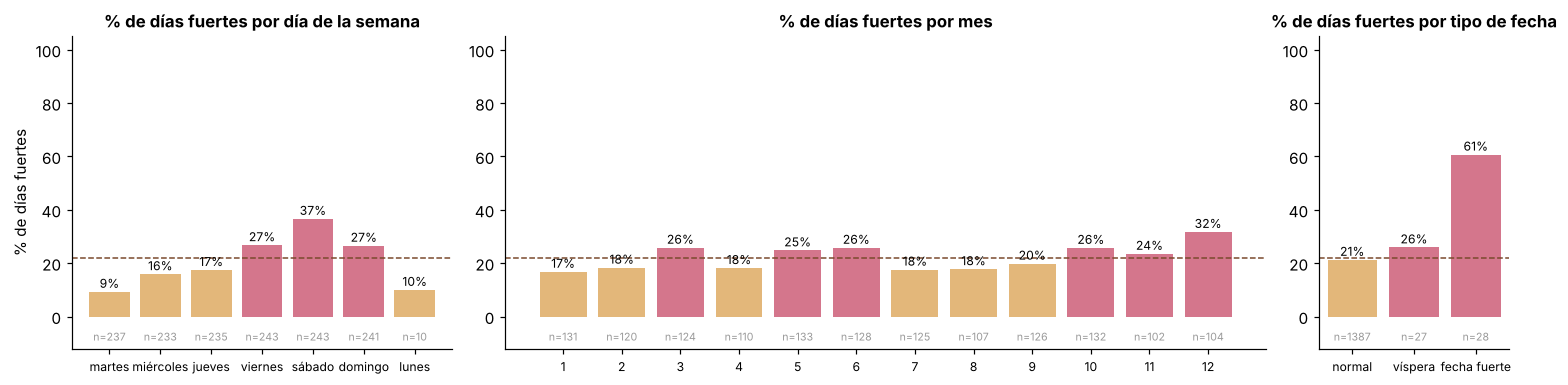

In [18]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6), gridspec_kw={"width_ratios": [6, 12, 3]})
for a, col, orden, titulo in [(ax[0], "dia_semana", DIAS[1:] + ["lunes"], "día de la semana"),
                              (ax[1], "mes", [str(m) for m in range(1, 13)], "mes"),
                              (ax[2], "tipo_fecha", ["normal", "víspera", "fecha fuerte"], "tipo de fecha")]:
    tasa = dias.groupby(col)["dia_fuerte"].mean().reindex(orden) * 100
    n = dias[col].value_counts().reindex(orden)
    a.bar(orden, tasa, color=[ROSA if v > 22.1 else ARENA for v in tasa])
    a.axhline(100 * dias["dia_fuerte"].mean(), color=CAFE, ls="--", lw=1)
    for i, (t, k) in enumerate(zip(tasa, n)):
        a.text(i, t + 1.5, f"{t:.0f}%", ha="center", fontsize=8)
        a.text(i, -9, f"n={k}", ha="center", fontsize=7, color=GRIS)
    a.set_title(f"% de días fuertes por {titulo}"); a.set_ylim(-12, 105)
    a.tick_params(axis="x", labelsize=8)
ax[0].set_ylabel("% de días fuertes"); plt.tight_layout(); plt.show()

El sábado es el día con más días fuertes (37%), seguido del viernes y el domingo (27%); de martes a jueves la tasa baja a entre 9% y 17%. Por mes, diciembre es el más alto (32%) y el resto del año se mueve entre 17% y 26%; los más bajos son enero, febrero, abril, julio y agosto (17% a 18%). Las fechas fuertes son días fuertes 61% de las veces, casi tres veces la tasa de un día normal, pero son muy pocas (28 en casi cinco años). Los 10 lunes son los que abrió por una fecha especial. Que estas variables sean categóricas y no numéricas importa: el sábado no es "más" que el viernes en una escala, así que en el Avance 2 se codifican con One-Hot.

In [19]:
print("Días de quincena fuertes: {:.1f}%  ·  fuera de quincena: {:.1f}%".format(
    100 * dias.loc[dias["quincena"] == 1, "dia_fuerte"].mean(), 100 * dias.loc[dias["quincena"] == 0, "dia_fuerte"].mean()))
tabla_q = pd.crosstab(dias["quincena"], dias["dia_fuerte"])
chi2, p, _, _ = stats.chi2_contingency(tabla_q)
print(f"Chi cuadrada de independencia: χ² = {chi2:.2f}, p = {p:.3f}")

Días de quincena fuertes: 22.8%  ·  fuera de quincena: 22.0%
Chi cuadrada de independencia: χ² = 0.05, p = 0.830


## 7. Distribuciones

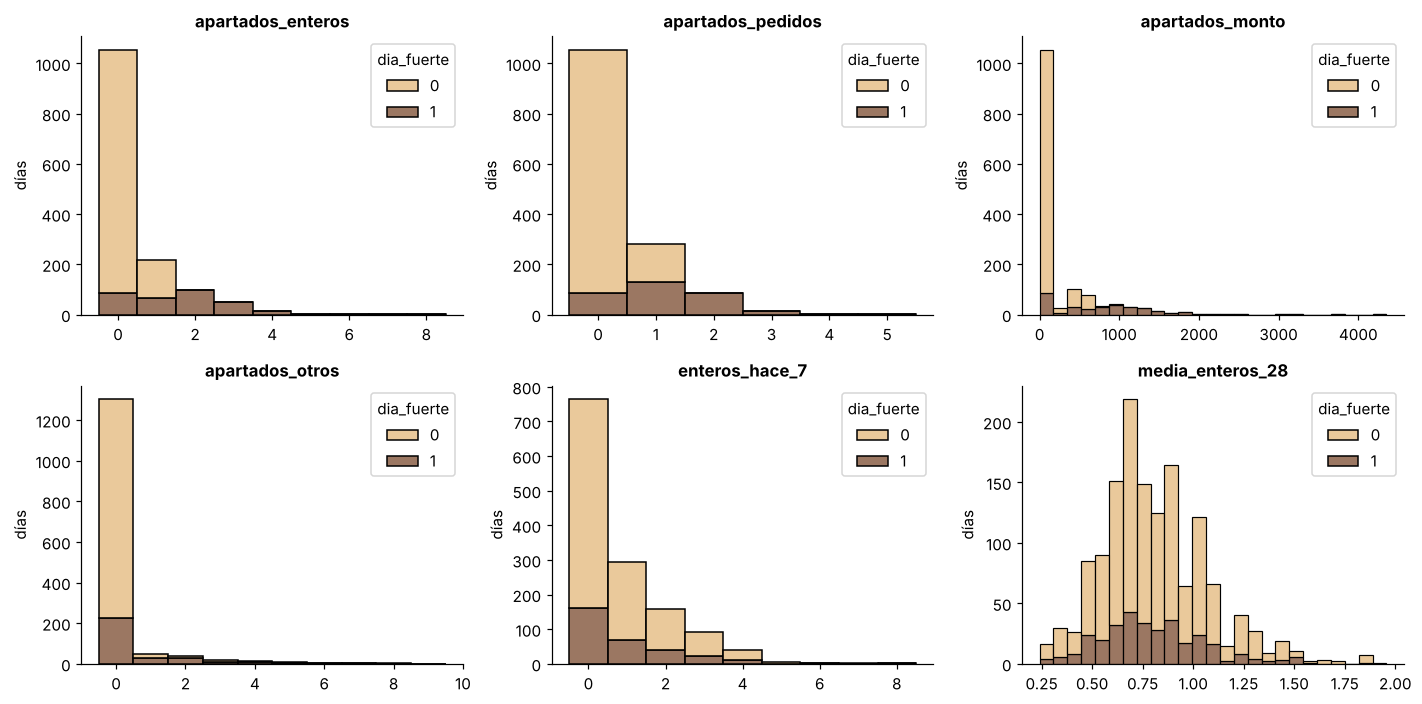

In [20]:
fig, axs = plt.subplots(2, 3, figsize=(13, 6.5))
for a, c in zip(axs.ravel(), NUMERICAS):
    sns.histplot(data=dias, x=c, hue="dia_fuerte", ax=a, palette={0: ARENA, 1: CAFE}, multiple="stack",
                 discrete=c in ["apartados_enteros", "apartados_pedidos", "apartados_otros", "enteros_hace_7"],
                 bins=None if c in ["apartados_enteros", "apartados_pedidos", "apartados_otros", "enteros_hace_7"] else 25)
    a.set_title(c); a.set_xlabel(""); a.set_ylabel("días")
plt.tight_layout(); plt.savefig(FIG / "eda_distribuciones.png", dpi=150); plt.show()

Café son los días fuertes y arena los normales. En `apartados_enteros` se ve la separación más clara: con 0 apartados solo 8% de los días terminan siendo fuertes, con 1 apartado 30%, y con 2 o más todos lo son (si ya hay dos apartados, el día es fuerte por definición). La parte difícil, y donde el modelo tiene que aportar, son los días con 0 o 1 apartado que se llenan en las últimas 48 horas: 85 de los 319 días fuertes llegaron con nada apartado dos días antes. En cambio, `enteros_hace_7` y `media_enteros_28` tienen casi la misma forma en las dos clases: cómo le fue la semana pasada o el último mes no anticipa el día.

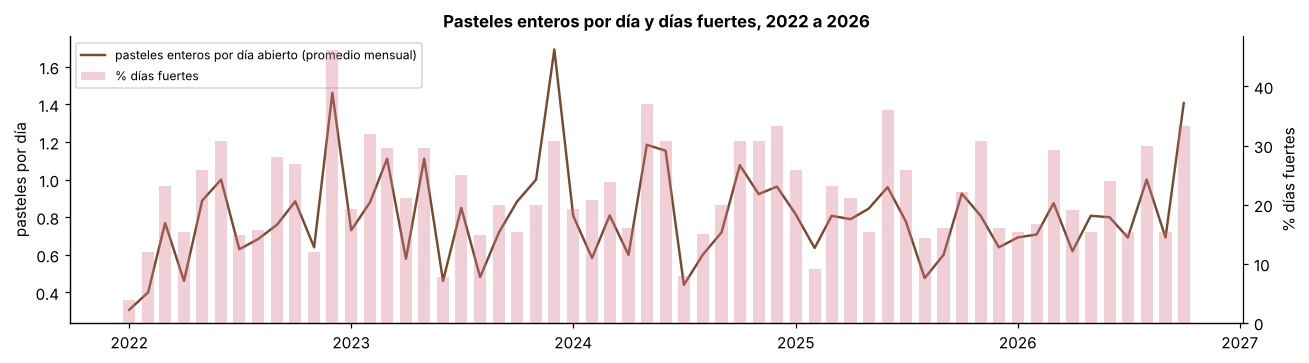

In [21]:
fig, ax = plt.subplots(figsize=(12, 3.4))
mensual = dias["enteros"].resample("MS").mean()
ax.plot(mensual.index, mensual, color=CAFE, lw=1.6, label="pasteles enteros por día abierto (promedio mensual)")
ax2 = ax.twinx()
ax2.bar(mensual.index, dias["dia_fuerte"].resample("MS").mean() * 100, width=20, color=ROSA, alpha=.35, label="% días fuertes")
ax2.set_ylabel("% días fuertes"); ax2.spines["right"].set_visible(True)
ax.set_title("Pasteles enteros por día y días fuertes, 2022 a 2026"); ax.set_ylabel("pasteles por día")
ax.legend(handles=ax.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0], loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

Los picos más altos caen en diciembre (2022 y 2023 sobre todo). Fuera de diciembre, el promedio mensual se mueve entre 0.5 y 1.3 pasteles por día desde 2022: el negocio llegó a lo que una persona puede hornear y ya no crece mucho. Como la serie tiene orden en el tiempo, en el Avance 2 la partición de entrenamiento y prueba se hace por fecha y no al azar.

## 8. Matriz de correlación

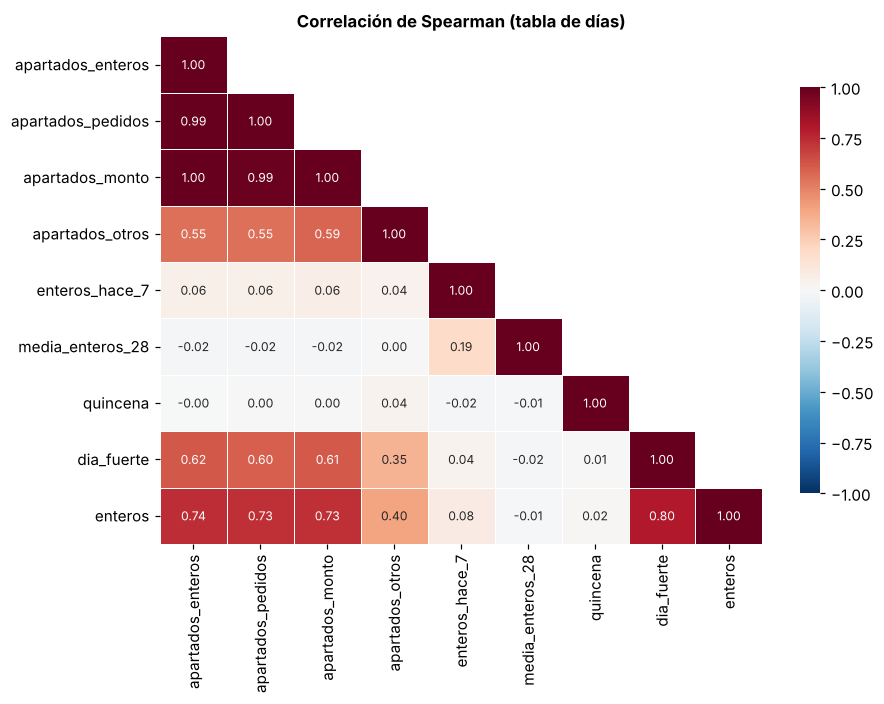

In [22]:
corr = dias[NUMERICAS + ["quincena", "dia_fuerte", "enteros"]].corr(method="spearman")
mascara = np.triu(np.ones_like(corr, dtype=bool), k=1)
plt.figure(figsize=(8.5, 6.5))
sns.heatmap(corr, mask=mascara, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            linewidths=.5, cbar_kws={"shrink": .8}, annot_kws={"size": 8})
plt.title("Correlación de Spearman (tabla de días)")
plt.tight_layout(); plt.savefig(FIG / "eda_correlacion.png", dpi=150); plt.show()

In [23]:
pearson = dias[NUMERICAS + ["quincena", "dia_fuerte"]].corr()["dia_fuerte"].drop("dia_fuerte")
pd.DataFrame({"Pearson": pearson, "Spearman": corr["dia_fuerte"].drop(["dia_fuerte", "enteros"])}).sort_values("Spearman", ascending=False)

,Pearson,Spearman
apartados_enteros,0.65,0.62
apartados_monto,0.63,0.61
apartados_pedidos,0.62,0.60
apartados_otros,0.29,0.35
enteros_hace_7,0.04,0.04
quincena,0.01,0.01
media_enteros_28,-0.02,-0.02


Usamos Spearman en el mapa porque las variables no son normales y tienen atípicos; Pearson se agrega para comparar. Lo más relevante:

- Con el objetivo, las más relacionadas son las de apartados: `apartados_enteros` (0.62), `apartados_monto` y `apartados_pedidos` (cerca de 0.60), y más abajo `apartados_otros` (0.35). La historia reciente casi no se relaciona: `enteros_hace_7` da 0.04 y `media_enteros_28` −0.02. La quincena tampoco (0.01), igual que encontramos en E1 con la prueba t.
- Entre explicativas, `apartados_enteros`, `apartados_pedidos` y `apartados_monto` están casi en 1 entre sí: dos días antes, lo que hay apartado son casi siempre pasteles enteros, así que contar piezas, pedidos o pesos da prácticamente lo mismo. Esa redundancia afecta a Naive Bayes, que supone independencia entre variables, y a KNN, que cuenta la misma información tres veces en la distancia. Los árboles la toleran. Por ahora las conservamos y lo tomamos en cuenta al comparar modelos.
- La correlación de cada variable con el objetivo se ve baja para la historia reciente, pero eso es solo relación lineal o monótona; el día de la semana y el mes, que son categóricos, no aparecen en esta matriz y sí separan las clases (sección 6.3).
- `enteros` aparece solo como referencia: es la variable de la que sale el objetivo y no puede entrar al modelo.

## 9. Nulos y atípicos en la tabla de días

In [24]:
print("Nulos por variable:", dias[NUMERICAS + CATEGORICAS + BINARIAS].isna().sum()[lambda s: s > 0].to_dict())
nulos_7 = dias[dias["enteros_hace_7"].isna()]
print(f"Los {len(nulos_7)} nulos de enteros_hace_7 caen en:", nulos_7.index.month.value_counts().sort_index().to_dict())
q1, q3 = dias[NUMERICAS].quantile(.25), dias[NUMERICAS].quantile(.75)
atipico = (dias[NUMERICAS] > q3 + 1.5 * (q3 - q1)) | (dias[NUMERICAS] < q1 - 1.5 * (q3 - q1))
pd.DataFrame({"atípicos (IQR)": atipico.sum(), "% de días": (100 * atipico.mean()).round(1),
              "de esos, % días fuertes": [100 * dias.loc[atipico[c], "dia_fuerte"].mean() if atipico[c].any() else np.nan for c in NUMERICAS],
              "de esos, en mayo, diciembre o fecha fuerte (%)": [100 * (dias.loc[atipico[c], "mes"].isin(["5", "12"]) |
                    (dias.loc[atipico[c], "tipo_fecha"] != "normal")).mean() if atipico[c].any() else np.nan for c in NUMERICAS]})

Nulos por variable: {'enteros_hace_7': 82}
Los 82 nulos de enteros_hace_7 caen en: {1: 7, 2: 5, 3: 2, 4: 24, 5: 4, 7: 2, 8: 30, 9: 3, 11: 2, 12: 3}


,atípicos (IQR),% de días,"de esos, % días fuertes","de esos, en mayo, diciembre o fecha fuerte (%)"
apartados_enteros,71,4.90,100.00,36.62
apartados_pedidos,19,1.30,100.00,68.42
apartados_monto,141,9.80,96.45,29.79
apartados_otros,138,9.60,66.67,29.71
enteros_hace_7,143,9.90,24.48,24.48
media_enteros_28,29,2.00,27.59,24.14


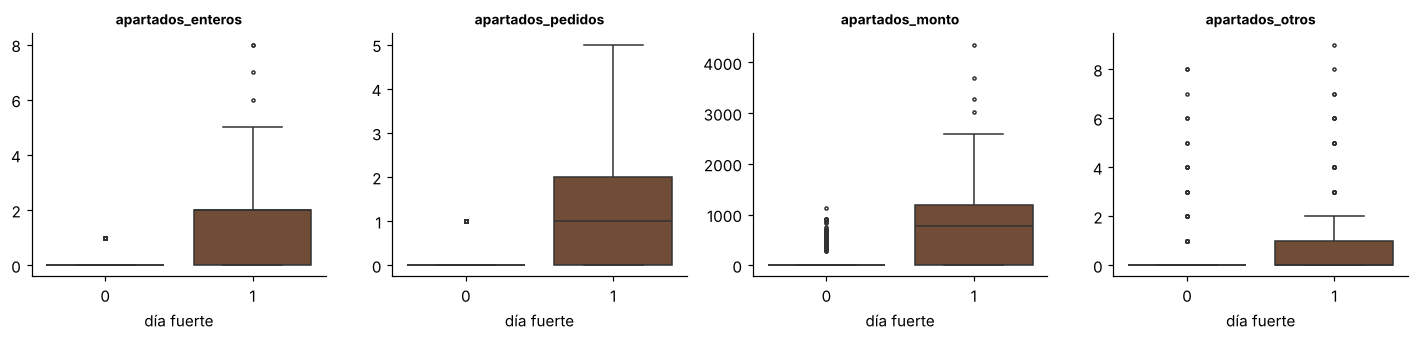

In [25]:
fig, ax = plt.subplots(1, 4, figsize=(13, 3.2))
for a, c in zip(ax, ["apartados_enteros", "apartados_pedidos", "apartados_monto", "apartados_otros"]):
    sns.boxplot(data=dias, x="dia_fuerte", y=c, ax=a, palette={0: ARENA, 1: CAFE}, hue="dia_fuerte", legend=False, fliersize=2)
    a.set_title(c, fontsize=9); a.set_xlabel("día fuerte"); a.set_ylabel("")
plt.tight_layout(); plt.show()

### Propuesta de tratamiento para la tabla de días

| Caso | Cuántos | Tratamiento | Razón |
|---|---|---|---|
| `enteros_hace_7` nulo (la semana anterior estuvo cerrada, sobre todo en sus vacaciones de Semana Santa y de agosto) | 82 días, 5.7% | Imputar con la mediana del entrenamiento, dentro del pipeline, y agregar una columna indicadora "semana anterior cerrada" | Borrar esos días quitaría justo los regresos de vacaciones. La mediana no se deja jalar por las semanas muy altas (la media sí); el indicador le avisa al modelo que ese valor fue imputado y no observado |
| Atípicos en las variables de apartados (días con muchos pedidos adelantados) | entre 1.3% y 9.8% de los días según la variable | Conservar | Son reales y son información: en `apartados_enteros`, `apartados_pedidos` y `apartados_monto` entre 96% y 100% de los días atípicos fueron días fuertes, alrededor de 70% en fin de semana. Son justo los que el modelo tiene que reconocer |
| Atípicos en `enteros_hace_7` y `media_enteros_28` | 9.9% y 2% | Conservar | Semanas buenas de verdad; no hay error de captura detrás |
| Escalas distintas (pesos contra conteos) | todas | Estandarizar con `StandardScaler` | KNN y SVM usan distancias; sin escalar, `apartados_monto` dominaría solo por estar en pesos |
| Categóricas (`dia_semana`, `mes`, `tipo_fecha`) | 3 variables | One-Hot | No tienen orden numérico |

Todo esto se ajusta solo con el periodo de entrenamiento para que el periodo de prueba no filtre información (por ejemplo, la mediana para imputar no puede incluir días del año de prueba).

## 10. Conclusiones del EDA

1. El conjunto final tiene 1,442 días abiertos (más de 500 registros) con 10 variables explicativas: 6 numéricas, 3 categóricas y 1 binaria. El objetivo es `dia_fuerte` y está desbalanceado (22% de días fuertes).
2. El archivo de pedidos traía errores de captura en cerca de 6% de los renglones. Ninguno se resolvió con la media: cada uno tiene una regla del negocio que da el valor correcto, y los irrecuperables se apartan.
3. Lo que más separa un día fuerte es lo que ya está apartado dos días antes, seguido del día de la semana (el sábado sobre todo), las fechas especiales y diciembre. La quincena y la historia reciente casi no aportan, y tres de las variables de apartados son casi redundantes entre sí.
4. Las variables numéricas no son normales y tienen colas largas por las fechas especiales. Los atípicos se conservan porque son información, no ruido.
5. Siguiente paso (Avance 2): pipeline con imputación, escalamiento y One-Hot; partición por fecha (entrenamiento hasta octubre de 2025, prueba el último año, aproximadamente 80/20) y comparación de Naive Bayes, KNN, SVM y árbol de decisión.

---
# Avance 2 · Preprocesamiento, partición y entrenamiento

Desde aquí se trabaja solo con la tabla de días que se guardó en la sección 5. Se vuelve a leer del CSV para que esta parte también corra sola.

In [26]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, fbeta_score,
                             confusion_matrix, ConfusionMatrixDisplay, make_scorer)

dias = pd.read_csv(DATOS / "dias_salome.csv", index_col="fecha", parse_dates=True, dtype={"mes": str})
NUMERICAS = ["apartados_enteros", "apartados_pedidos", "apartados_monto", "apartados_otros",
             "enteros_hace_7", "media_enteros_28"]
CATEGORICAS = ["dia_semana", "mes", "tipo_fecha"]
BINARIAS = ["quincena"]
X, y = dias[NUMERICAS + CATEGORICAS + BINARIAS], dias["dia_fuerte"]
print(X.shape, "· días fuertes:", int(y.sum()))

(1442, 10) · días fuertes: 319


## 11. Partición de los datos

Los días tienen orden en el tiempo. Si revolviéramos al azar, el modelo entrenaría con días de diciembre de 2025 para "predecir" noviembre de 2025, algo que en la realidad no puede pasar. Por eso la partición es cronológica:

- Entrenamiento: del 1 de enero de 2022 al 31 de octubre de 2025.
- Prueba: del 1 de noviembre de 2025 al 31 de octubre de 2026, un año completo con todas sus temporadas.

Queda en una proporción cercana a 80/20. Dentro del entrenamiento se hace además validación cruzada temporal con `TimeSeriesSplit` de 5 bloques: cada bloque entrena con el pasado y valida con el periodo siguiente, que es la versión de K-Fold que respeta el tiempo.

In [27]:
CORTE = "2025-11-01"
X_train, X_test = X[X.index < CORTE], X[X.index >= CORTE]
y_train, y_test = y[y.index < CORTE], y[y.index >= CORTE]
print(f"Entrenamiento: {len(X_train):,} días ({len(X_train) / len(X):.1%}) · {y_train.mean():.1%} fuertes")
print(f"Prueba:        {len(X_test):,} días ({len(X_test) / len(X):.1%}) · {y_test.mean():.1%} fuertes")

cv = TimeSeriesSplit(n_splits=5)
for i, (a, b) in enumerate(cv.split(X_train), 1):
    print(f"  bloque {i}: entrena {X_train.index[a[0]]:%Y-%m-%d} a {X_train.index[a[-1]]:%Y-%m-%d} ({len(a)})"
          f"  ·  valida {X_train.index[b[0]]:%Y-%m-%d} a {X_train.index[b[-1]]:%Y-%m-%d} ({len(b)})")

Entrenamiento: 1,146 días (79.5%) · 22.3% fuertes
Prueba:        296 días (20.5%) · 21.6% fuertes
  bloque 1: entrena 2022-01-02 a 2022-08-17 (191)  ·  valida 2022-08-18 a 2023-03-31 (191)
  bloque 2: entrena 2022-01-02 a 2023-03-31 (382)  ·  valida 2023-04-01 a 2023-11-24 (191)
  bloque 3: entrena 2022-01-02 a 2023-11-24 (573)  ·  valida 2023-11-25 a 2024-07-16 (191)
  bloque 4: entrena 2022-01-02 a 2024-07-16 (764)  ·  valida 2024-07-17 a 2025-03-06 (191)
  bloque 5: entrena 2022-01-02 a 2025-03-06 (955)  ·  valida 2025-03-07 a 2025-10-31 (191)


## 12. Preprocesamiento e ingeniería de características

Un solo `ColumnTransformer` que se ajusta únicamente con el entrenamiento:

- Numéricas: imputación de nulos con la mediana (solo `enteros_hace_7` tiene nulos) más una columna indicadora de que el valor faltaba, y estandarización a media 0 y desviación 1.
- Categóricas: imputación con la moda (por si algún día llega vacío en datos nuevos) y codificación One-Hot. `handle_unknown="ignore"` evita que el modelo falle si aparece una categoría que no vio.
- Binaria (`quincena`): pasa tal cual, ya está en 0 y 1.

Va dentro de un `Pipeline` con cada modelo. Así, en la validación cruzada, la mediana y la escala se recalculan en cada bloque solo con su parte de entrenamiento.

In [28]:
preprocesamiento = ColumnTransformer([
    ("numericas", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), NUMERICAS),
    ("categoricas", make_pipeline(SimpleImputer(strategy="most_frequent"),
                                  OneHotEncoder(handle_unknown="ignore", sparse_output=False)), CATEGORICAS),
    ("binarias", "passthrough", BINARIAS)], verbose_feature_names_out=False)

Xt = preprocesamiento.fit(X_train).transform(X_train)
nombres = preprocesamiento.get_feature_names_out()
print(f"{X_train.shape[1]} variables originales -> {Xt.shape[1]} columnas después de One-Hot")
print("Mediana usada para imputar enteros_hace_7:", preprocesamiento.named_transformers_["numericas"][0].statistics_[NUMERICAS.index("enteros_hace_7")])
print("Columnas:", list(nombres))
muestra = ["apartados_enteros", "enteros_hace_7", "missingindicator_enteros_hace_7", "dia_semana_sábado",
           "dia_semana_viernes", "mes_12", "tipo_fecha_fecha fuerte", "quincena"]
pd.DataFrame(Xt, columns=nombres, index=X_train.index).loc["2022-01-02":"2022-01-09", muestra].round(2)

10 variables originales -> 30 columnas después de One-Hot
Mediana usada para imputar enteros_hace_7: 0.0
Columnas: ['apartados_enteros', 'apartados_pedidos', 'apartados_monto', 'apartados_otros', 'enteros_hace_7', 'media_enteros_28', 'missingindicator_enteros_hace_7', 'dia_semana_domingo', 'dia_semana_jueves', 'dia_semana_lunes', 'dia_semana_martes', 'dia_semana_miércoles', 'dia_semana_sábado', 'dia_semana_viernes', 'mes_1', 'mes_10', 'mes_11', 'mes_12', 'mes_2', 'mes_3', 'mes_4', 'mes_5', 'mes_6', 'mes_7', 'mes_8', 'mes_9', 'tipo_fecha_fecha fuerte', 'tipo_fecha_normal', 'tipo_fecha_víspera', 'quincena']


,apartados_enteros,enteros_hace_7,missingindicator_enteros_hace_7,dia_semana_sábado,dia_semana_viernes,mes_12,tipo_fecha_fecha fuerte,quincena
fecha,,,,,,,,
2022-01-02,-0.49,-0.67,-0.25,0.00,0.00,0.00,0.00,0.00
2022-01-03,-0.49,-0.67,4.08,0.00,0.00,0.00,0.00,0.00
2022-01-04,-0.49,-0.67,-0.25,0.00,0.00,0.00,0.00,0.00
2022-01-05,-0.49,-0.67,-0.25,0.00,0.00,0.00,0.00,0.00
2022-01-06,0.60,0.20,-0.25,0.00,0.00,0.00,1.00,0.00
2022-01-07,-0.49,2.81,-0.25,0.00,1.00,0.00,0.00,0.00
2022-01-08,0.60,-0.67,4.08,1.00,0.00,0.00,0.00,0.00
2022-01-09,-0.49,-0.67,-0.25,0.00,0.00,0.00,0.00,0.00


In [29]:
ver = pd.DataFrame(Xt[:, :len(NUMERICAS)], columns=NUMERICAS)   # las primeras columnas son las numéricas ya escaladas
pd.DataFrame({"media": ver.mean(), "desv. estándar": ver.std(), "nulos": ver.isna().sum()}).round(3)

,media,desv. estándar,nulos
apartados_enteros,0.00,1.00,0
apartados_pedidos,0.00,1.00,0
apartados_monto,0.00,1.00,0
apartados_otros,0.00,1.00,0
enteros_hace_7,-0.00,1.00,0
media_enteros_28,-0.00,1.00,0


## 13. Entrenamiento de los modelos

Cuatro algoritmos de la Unidad 3, con sus hiperparámetros por omisión en esta primera vuelta (la optimización va en la entrega final):

| Modelo | Idea |
|---|---|
| Naive Bayes gaussiano | Probabilidad de cada clase suponiendo variables independientes y normales |
| KNN (k = 5) | Mira los 5 días más parecidos del entrenamiento y vota |
| SVM con kernel RBF | Busca la frontera de mayor margen entre clases en un espacio transformado |
| Árbol de decisión | Preguntas sucesivas sobre las variables hasta llegar a una hoja |

Se agregan dos referencias para saber si los modelos aportan algo: la clase mayoritaria (siempre "día normal") y la regla simple que Salomé puede aplicar de memoria, la misma que usamos de referencia en E3: "si ya tengo un pastel apartado y es de viernes a domingo, o ya tengo dos, va a ser fuerte".

In [30]:
modelos = {
    "Naive Bayes": GaussianNB(),
    "KNN (k=5)": KNeighborsClassifier(),
    "SVM (RBF)": SVC(random_state=SEMILLA),
    "Árbol de decisión": DecisionTreeClassifier(random_state=SEMILLA),
}
f2 = make_scorer(fbeta_score, beta=2)
metricas_cv = {"accuracy": "accuracy", "precision": make_scorer(precision_score, zero_division=0),
               "recall": "recall", "f1": "f1", "f2": f2}

def evaluar(y_real, y_pred):
    return {"Accuracy": accuracy_score(y_real, y_pred), "Precision": precision_score(y_real, y_pred, zero_division=0),
            "Recall": recall_score(y_real, y_pred), "F1": f1_score(y_real, y_pred), "F2": fbeta_score(y_real, y_pred, beta=2)}

def regla_simple(X_):
    fin_de_semana = X_["dia_semana"].isin(["viernes", "sábado", "domingo"])
    return (((X_["apartados_enteros"] >= 1) & fin_de_semana) | (X_["apartados_enteros"] >= 2)).astype(int).to_numpy()

filas, ajustados, predicciones = [], {}, {}
for nombre, modelo in {"Clase mayoritaria": DummyClassifier(strategy="most_frequent"), **modelos}.items():
    pipe = Pipeline([("pre", preprocesamiento), ("modelo", modelo)])
    cvr = cross_validate(pipe, X_train, y_train, cv=cv, scoring=metricas_cv)
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    ajustados[nombre], predicciones[nombre] = pipe, pred
    filas.append({"Modelo": nombre, "F1 en CV": cvr["test_f1"].mean(), "± (desv.)": cvr["test_f1"].std(),
                  "F2 en CV": cvr["test_f2"].mean(), **evaluar(y_test, pred)})
predicciones["Regla simple"] = regla_simple(X_test)
filas.append({"Modelo": "Regla simple", "F1 en CV": f1_score(y_train, regla_simple(X_train)), "± (desv.)": np.nan,
              "F2 en CV": fbeta_score(y_train, regla_simple(X_train), beta=2), **evaluar(y_test, predicciones["Regla simple"])})
comparativa = pd.DataFrame(filas).set_index("Modelo")

## 14. Tabla comparativa preliminar

In [31]:
comparativa.round(3).style.format("{:.3f}", na_rep="—").background_gradient(
    subset=["Accuracy", "Precision", "Recall", "F1", "F2"], cmap="YlOrBr")

,F1 en CV,± (desv.),F2 en CV,Accuracy,Precision,Recall,F1,F2
Modelo,,,,,,,,
Clase mayoritaria,0.000,0.000,0.000,0.784,0.000,0.000,0.000,0.000
Naive Bayes,0.567,0.062,0.674,0.831,0.588,0.734,0.653,0.699
KNN (k=5),0.641,0.067,0.570,0.909,0.930,0.625,0.748,0.669
SVM (RBF),0.650,0.071,0.550,0.912,1.000,0.594,0.745,0.646
Árbol de decisión,0.628,0.096,0.614,0.841,0.627,0.656,0.641,0.650
Regla simple,0.685,—,0.664,0.872,0.691,0.734,0.712,0.725


Las columnas de CV son el promedio de los 5 bloques de validación dentro del entrenamiento (para la regla, que no se entrena, es su resultado en todo el periodo de entrenamiento). Las de la derecha son el año de prueba, que ningún modelo vio.

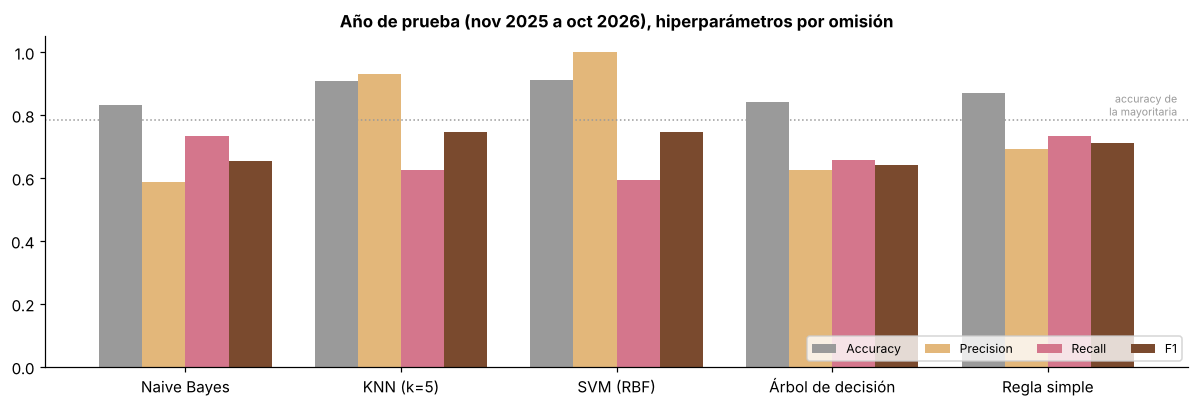

In [32]:
fig, ax = plt.subplots(figsize=(11, 3.8))
comparativa.drop(index="Clase mayoritaria")[["Accuracy", "Precision", "Recall", "F1"]].plot.bar(
    ax=ax, rot=0, color=[GRIS, ARENA, ROSA, CAFE], width=.8)
ax.axhline(comparativa.loc["Clase mayoritaria", "Accuracy"], color=GRIS, ls=":", lw=1)
ax.text(4.6, comparativa.loc["Clase mayoritaria", "Accuracy"] + .015, "accuracy de\nla mayoritaria", fontsize=7, color=GRIS, ha="right")
ax.set_ylim(0, 1.05); ax.set_title("Año de prueba (nov 2025 a oct 2026), hiperparámetros por omisión")
ax.legend(ncol=4, fontsize=8, loc="lower right"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

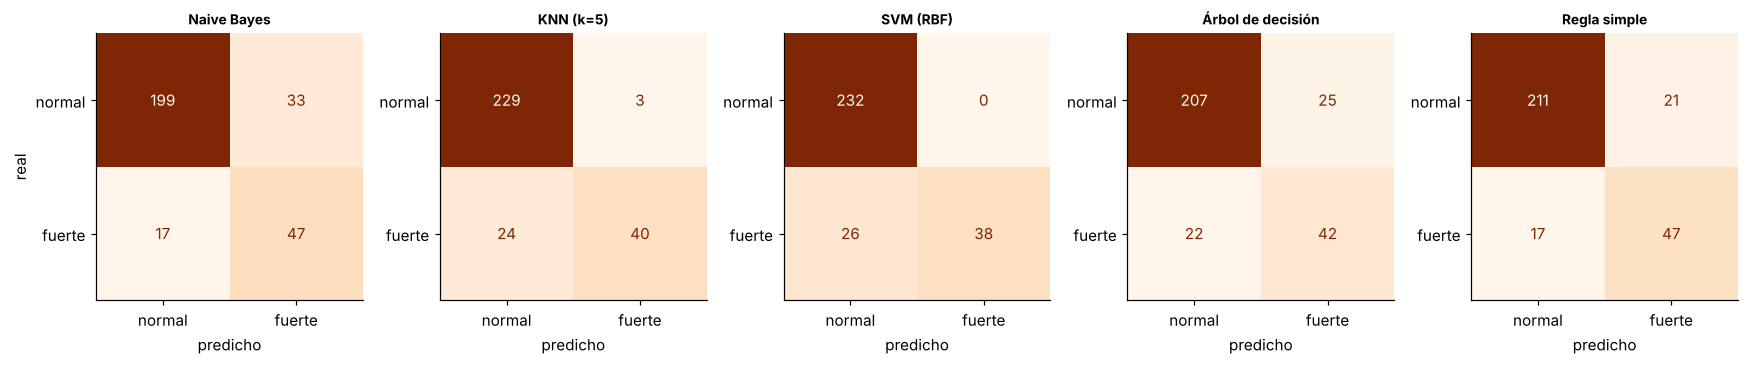

In [33]:
fig, axs = plt.subplots(1, 5, figsize=(16, 3.2))
for a, nombre in zip(axs, list(modelos) + ["Regla simple"]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, predicciones[nombre]), display_labels=["normal", "fuerte"]).plot(
        ax=a, colorbar=False, cmap="Oranges")
    a.set_title(nombre, fontsize=9); a.set_xlabel("predicho"); a.set_ylabel("real" if a is axs[0] else "")
plt.tight_layout(); plt.show()

## 15. Lectura preliminar

- La exactitud engaña. La clase mayoritaria acierta 78% de los días del año de prueba sin avisar ni un solo día fuerte. Un modelo puede tener más de 90% de exactitud y aun así dejar pasar más de un tercio de los días que importan.
- SVM y KNN con sus valores por omisión son conservadores. Tienen la mejor exactitud (0.91) y la mejor precisión, pero el recall más bajo. El SVM marcó como fuertes exactamente 38 días, que son los 38 días del año de prueba que ya tenían dos o más pasteles apartados: aprendió la parte obvia y nada más. Para Salomé eso significa seguir rechazando pedidos en los 26 días fuertes que se llenaron en las últimas 48 horas.
- Naive Bayes tiene el recall más alto (0.73) a cambio de más falsas alarmas, y es el mejor modelo en F2 en esta vuelta, aun con variables que no son normales y que están correlacionadas entre sí.
- El árbol sin límite de profundidad memoriza. Llega a 21 niveles y 199 hojas, con F1 de 0.99 en entrenamiento y 0.64 en prueba: sobreajuste claro (ver la celda de abajo). Limitar la profundidad es lo primero que hay que probar.
- La regla simple ya es buena, porque se apoya en la variable más fuerte. Ningún modelo con valores por omisión la supera en F2 (0.725 contra 0.699 del mejor). KNN y SVM la pasan en F1 y en exactitud, pero solo porque se equivocan menos hacia arriba; dejan pasar más días fuertes. Esa regla es la vara que deben superar los modelos optimizados.
- Entre la validación cruzada y la prueba las cifras de prueba salen un poco más altas, porque los primeros bloques de validación entrenan con pocos meses de 2022. El orden general se parece: SVM y KNN arriba en F1, Naive Bayes arriba en F2.

Siguiente paso: optimizar hiperparámetros con búsqueda en rejilla sobre la misma validación temporal, usando F2 como criterio (pesa el recall el doble, por la asimetría de costos de la sección 1), y probar `class_weight="balanced"` en SVM y el árbol para compensar el desbalance.

In [34]:
arbol = ajustados["Árbol de decisión"]
print("Profundidad del árbol sin límite:", arbol.named_steps["modelo"].get_depth(),
      "· hojas:", arbol.named_steps["modelo"].get_n_leaves())
print(f"F1 en entrenamiento: {f1_score(y_train, arbol.predict(X_train)):.3f}  ·  en prueba: {f1_score(y_test, predicciones['Árbol de decisión']):.3f}")

Profundidad del árbol sin límite: 21 · hojas: 199
F1 en entrenamiento: 0.994  ·  en prueba: 0.641


---
# Entrega final · Optimización, selección e interpretación

In [35]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.inspection import permutation_importance
from sklearn.tree import plot_tree
import json, time

## 16. Optimización de hiperparámetros

Búsqueda en rejilla (`GridSearchCV`) con la misma validación temporal de 5 bloques y F2 como criterio. La rejilla de cada modelo cubre los hiperparámetros que más cambian su comportamiento. El año de prueba no participa en ninguna decisión de esta sección.

En el árbol pedimos al menos 5 días por hoja: una regla que se apoya en uno o dos días es memoria, no patrón, y Salomé necesita reglas que se puedan leer y confiar. En `class_weight="balanced"` cada día fuerte pesa más o menos 3.5 veces un día normal, que compensa el desbalance de 22% contra 78%.

In [36]:
rejillas = {
    "Naive Bayes": (GaussianNB(), {"modelo__var_smoothing": [1e-9, 1e-6, 1e-3, 1e-2, 1e-1]}),
    "KNN": (KNeighborsClassifier(), {"modelo__n_neighbors": [3, 5, 11, 21, 31, 51],
                                     "modelo__weights": ["uniform", "distance"], "modelo__p": [1, 2]}),
    "SVM (RBF)": (SVC(random_state=SEMILLA), {"modelo__C": [0.1, 0.3, 1, 3, 10], "modelo__gamma": ["scale", 0.01, 0.03, 0.1],
                                              "modelo__class_weight": [None, "balanced"]}),
    "Árbol de decisión": (DecisionTreeClassifier(random_state=SEMILLA), {"modelo__max_depth": [2, 3, 4, 5, 6, None],
                          "modelo__min_samples_leaf": [5, 10, 20, 40], "modelo__class_weight": [None, "balanced"]}),
}
busquedas, filas_opt = {}, []
for nombre, (modelo, rejilla) in rejillas.items():
    inicio = time.perf_counter()
    gs = GridSearchCV(Pipeline([("pre", preprocesamiento), ("modelo", modelo)]), rejilla, cv=cv, scoring=f2, n_jobs=-1)
    gs.fit(X_train, y_train)
    busquedas[nombre] = gs
    i = gs.best_index_
    filas_opt.append({"Modelo": nombre, "combinaciones": len(gs.cv_results_["params"]),
                      "mejores hiperparámetros": {k.replace("modelo__", ""): v for k, v in gs.best_params_.items()},
                      "F2 en CV": gs.best_score_, "±": gs.cv_results_["std_test_score"][i],
                      "segundos": round(time.perf_counter() - inicio, 1)})
optimizacion = pd.DataFrame(filas_opt).set_index("Modelo").sort_values("F2 en CV", ascending=False)
optimizacion

,combinaciones,mejores hiperparámetros,F2 en CV,±,segundos
Modelo,,,,,
Árbol de decisión,48,"{'class_weight': 'balanced', 'max_depth': 3, '...",0.69,0.06,3.20
SVM (RBF),40,"{'C': 0.3, 'class_weight': 'balanced', 'gamma'...",0.69,0.06,3.90
Naive Bayes,5,{'var_smoothing': 1e-06},0.68,0.06,1.70
KNN,24,"{'n_neighbors': 3, 'p': 2, 'weights': 'distance'}",0.61,0.06,1.70


En E3 se desplegó una primera versión de este clasificador con 13 variables (4 numéricas y 9 indicadores de calendario), sin imputación ni One-Hot completo del día de la semana y el mes; ahí ganó un árbol de profundidad 2 con F2 de 0.74 en el mismo año de prueba. Esta versión amplía el preprocesamiento y la rejilla.

La selección se hace aquí, con la validación cruzada, antes de mirar la prueba. El modelo con mejor F2 en validación es el que se elige; la prueba sirve para confirmar que el resultado se sostiene con datos nuevos.

In [37]:
elegido = optimizacion.index[0]
print("Modelo elegido por validación cruzada:", elegido, optimizacion.loc[elegido, "mejores hiperparámetros"])

Modelo elegido por validación cruzada: Árbol de decisión {'class_weight': 'balanced', 'max_depth': 3, 'min_samples_leaf': 5}


## 17. Evaluación en el año de prueba

In [38]:
filas_fin, pred_fin, prob_fin = [], {}, {}
for nombre, gs in busquedas.items():
    m = gs.best_estimator_
    pred_fin[nombre] = m.predict(X_test)
    puntaje = m.decision_function(X_test) if hasattr(m, "decision_function") else m.predict_proba(X_test)[:, 1]
    prob_fin[nombre] = puntaje
    filas_fin.append({"Modelo": nombre, "F2 en CV": busquedas[nombre].best_score_, **evaluar(y_test, pred_fin[nombre]),
                      "AUC": roc_auc_score(y_test, puntaje)})
pred_fin["Regla simple"] = predicciones["Regla simple"]
filas_fin.append({"Modelo": "Regla simple", "F2 en CV": comparativa.loc["Regla simple", "F2 en CV"],
                  **evaluar(y_test, pred_fin["Regla simple"]), "AUC": np.nan})
final = pd.DataFrame(filas_fin).set_index("Modelo")
final.round(3).style.format("{:.3f}", na_rep="—").background_gradient(subset=["Accuracy", "Precision", "Recall", "F1", "F2", "AUC"], cmap="YlOrBr")

,F2 en CV,Accuracy,Precision,Recall,F1,F2,AUC
Modelo,,,,,,,
Naive Bayes,0.676,0.831,0.588,0.734,0.653,0.699,0.851
KNN,0.606,0.851,0.656,0.656,0.656,0.656,0.828
SVM (RBF),0.686,0.851,0.625,0.781,0.694,0.744,0.878
Árbol de decisión,0.694,0.858,0.645,0.766,0.700,0.738,0.869
Regla simple,0.664,0.872,0.691,0.734,0.712,0.725,—


In [39]:
antes_despues = pd.DataFrame({"F2 por omisión": comparativa.loc[["Naive Bayes", "KNN (k=5)", "SVM (RBF)", "Árbol de decisión"], "F2"].to_numpy(),
                              "F2 optimizado": final.loc[list(busquedas), "F2"].to_numpy(),
                              "Recall por omisión": comparativa.loc[["Naive Bayes", "KNN (k=5)", "SVM (RBF)", "Árbol de decisión"], "Recall"].to_numpy(),
                              "Recall optimizado": final.loc[list(busquedas), "Recall"].to_numpy()}, index=list(busquedas))
antes_despues["mejora F2"] = antes_despues["F2 optimizado"] - antes_despues["F2 por omisión"]
antes_despues.round(3)

,F2 por omisión,F2 optimizado,Recall por omisión,Recall optimizado,mejora F2
Naive Bayes,0.70,0.70,0.73,0.73,0.00
KNN,0.67,0.66,0.62,0.66,-0.01
SVM (RBF),0.65,0.74,0.59,0.78,0.10
Árbol de decisión,0.65,0.74,0.66,0.77,0.09


Lo que dejó la optimización:

- SVM y árbol mejoran casi 0.10 en F2. En los dos el cambio que más pesa es `class_weight="balanced"`: al pesar más los días fuertes, el recall sube de 0.59 a 0.78 en el SVM y de 0.66 a 0.77 en el árbol. El árbol además dejó de memorizar: con profundidad 3 y al menos 5 días por hoja pasa de 199 hojas a 7.
- Naive Bayes no cambia: su único hiperparámetro (el suavizado de varianza) casi no mueve nada con estos datos.
- KNN empeora un poco en prueba aunque mejoró en validación. La búsqueda eligió k = 3, un vecindario muy chico que se ajusta a los bloques de validación y no se sostiene con datos nuevos. Optimizar no garantiza mejorar; por eso se confirma con un periodo que nadie vio.
- El árbol, elegido en validación, también queda entre los dos mejores en prueba. El SVM lo pasa por un día (F2 de 0.744 contra 0.738, con 14 días fuertes perdidos contra 15). Nos quedamos con el árbol porque la decisión se tomó antes de ver la prueba, la diferencia es de un día en todo un año y el árbol se puede leer y explicar a Salomé; el SVM no.

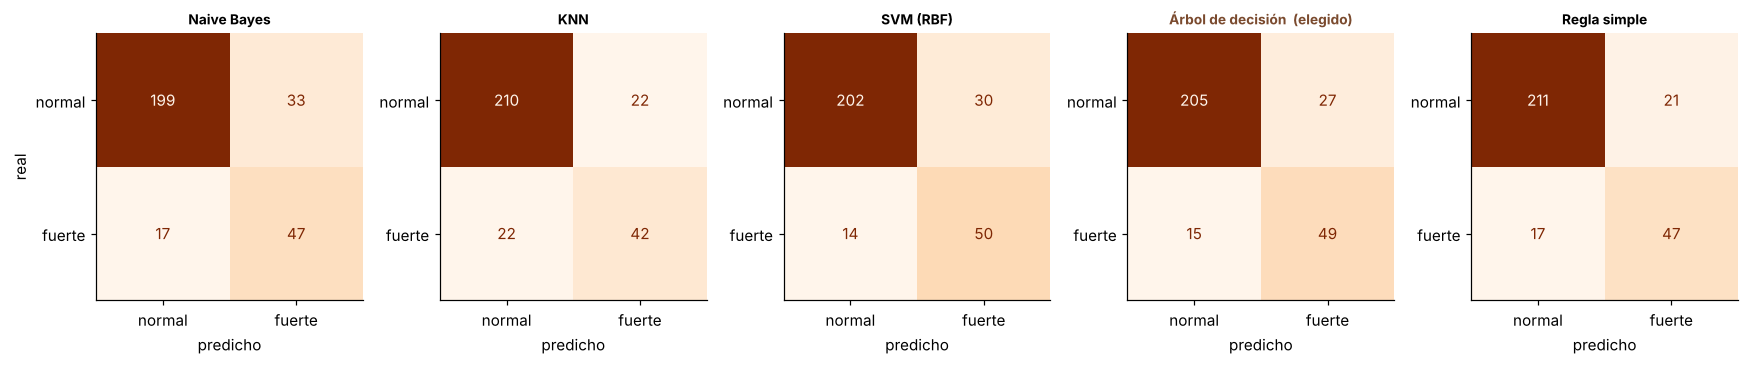

In [40]:
fig, axs = plt.subplots(1, 5, figsize=(16, 3.3))
for a, nombre in zip(axs, list(busquedas) + ["Regla simple"]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred_fin[nombre]), display_labels=["normal", "fuerte"]).plot(
        ax=a, colorbar=False, cmap="Oranges")
    a.set_title(nombre + ("  (elegido)" if nombre == elegido else ""), fontsize=9, color=CAFE if nombre == elegido else "black")
    a.set_xlabel("predicho"); a.set_ylabel("real" if a is axs[0] else "")
plt.tight_layout(); plt.savefig(FIG / "final_matrices.png", dpi=150); plt.show()

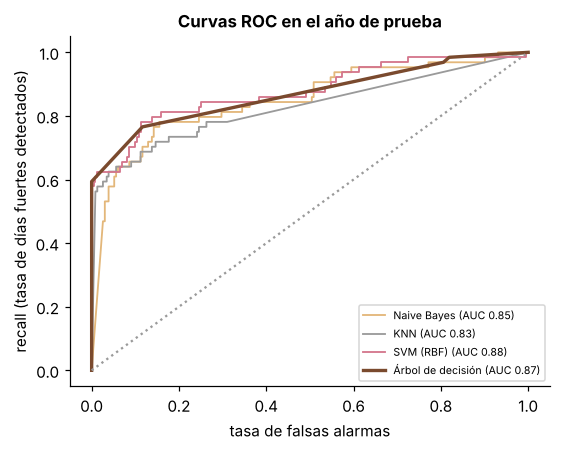

In [41]:
fig, ax = plt.subplots(figsize=(5.2, 4.2))
for nombre, color in zip(busquedas, [ARENA, GRIS, ROSA, CAFE]):
    fpr, tpr, _ = roc_curve(y_test, prob_fin[nombre])
    ax.plot(fpr, tpr, color=color, lw=2.2 if nombre == elegido else 1.2,
            label=f"{nombre} (AUC {roc_auc_score(y_test, prob_fin[nombre]):.2f})")
ax.plot([0, 1], [0, 1], ls=":", color=GRIS); ax.set_title("Curvas ROC en el año de prueba"); ax.legend(fontsize=7)
ax.set_xlabel("tasa de falsas alarmas"); ax.set_ylabel("recall (tasa de días fuertes detectados)")
plt.tight_layout(); plt.show()

## 18. El costo para Salomé

Pasamos la matriz de confusión a pesos con los costos de la sección 1: cada día fuerte que no se ve venir le cuesta en promedio un pedido rechazado (unos 500 pesos) y cada falsa alarma le deja una base de más (unos 150 pesos en insumos). Es una aproximación: un día fuerte perdido puede costar más de un pedido. Se compara con no usar nada (preparar siempre un solo pastel) y con su regla.

In [42]:
COSTO_FN, COSTO_FP = 500, 150
def costo(pred):
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return {"días fuertes que pasó por alto": fn, "falsas alarmas": fp, "costo estimado del año (MXN)": fn * COSTO_FN + fp * COSTO_FP}
costos = pd.DataFrame({"Sin modelo (siempre 1 pastel)": costo(np.zeros(len(y_test), dtype=int)),
                       **{n: costo(pred_fin[n]) for n in ["Regla simple"] + list(busquedas)}}).T
costos["ahorro contra no hacer nada"] = costos.iloc[0, 2] - costos["costo estimado del año (MXN)"]
costos.sort_values("costo estimado del año (MXN)")

,días fuertes que pasó por alto,falsas alarmas,costo estimado del año (MXN),ahorro contra no hacer nada
SVM (RBF),14,30,11500,20500
Árbol de decisión,15,27,11550,20450
Regla simple,17,21,11650,20350
Naive Bayes,17,33,13450,18550
KNN,22,22,14300,17700
Sin modelo (siempre 1 pastel),64,0,32000,0


Anticipar los días fuertes, con cualquier método razonable, le ahorraría a Salomé alrededor de 20,000 pesos al año contra no anticipar nada (64 días fuertes × 500 pesos). Entre los mejores modelos y la regla simple la diferencia es de unos 100 pesos a 150 pesos al año, que es ruido. Esto es un hallazgo en sí mismo: con la información que hay dos días antes, el modelo llega a la misma conclusión que la regla simple, y no la mejora de forma que valga la pena.

## 19. Análisis de errores del modelo elegido

In [43]:
modelo = busquedas[elegido].best_estimator_
res = X_test.copy()
res["real"], res["predicho"], res["enteros"] = y_test, pred_fin[elegido], dias.loc[X_test.index, "enteros"]
res["resultado"] = np.select([(res.real == 1) & (res.predicho == 1), (res.real == 0) & (res.predicho == 0),
                              (res.real == 1) & (res.predicho == 0)], ["acierto fuerte", "acierto normal", "falso negativo"], "falso positivo")
print(res["resultado"].value_counts().to_string())
pd.crosstab(res["apartados_enteros"].clip(upper=2).map({0: "0 apartados", 1: "1 apartado", 2: "2 o más"}), res["resultado"])

resultado
acierto normal    205
acierto fuerte     49
falso positivo     27
falso negativo     15


resultado,acierto fuerte,acierto normal,falso negativo,falso positivo
apartados_enteros,,,,
0 apartados,0,202,14,0
1 apartado,11,3,1,27
2 o más,38,0,0,0


In [44]:
pd.crosstab(res["dia_semana"], res["resultado"]).reindex(DIAS[1:] + ["lunes"]).dropna(how="all").fillna(0).astype(int)

resultado,acierto fuerte,acierto normal,falso negativo,falso positivo
dia_semana,,,,
martes,1,45,2,0
miércoles,4,40,3,1
jueves,2,40,1,5
viernes,12,30,3,5
sábado,16,25,2,8
domingo,14,24,4,8
lunes,0,1,0,0


In [45]:
fn = res[res["resultado"] == "falso negativo"]
print(f"Falsos negativos: {len(fn)}. Pasteles enteros que sí se entregaron esos días:", fn["enteros"].value_counts().to_dict())
fn[["dia_semana", "mes", "tipo_fecha", "apartados_enteros", "apartados_pedidos", "media_enteros_28", "enteros"]].head(12)

Falsos negativos: 15. Pasteles enteros que sí se entregaron esos días: {2: 10, 3: 3, 4: 2}


,dia_semana,mes,tipo_fecha,apartados_enteros,apartados_pedidos,media_enteros_28,enteros
fecha,,,,,,,
2025-11-02,domingo,11,normal,0,0,1.04,4
2025-11-08,sábado,11,normal,0,0,1.08,2
2025-11-16,domingo,11,normal,0,0,0.88,2
2025-11-27,jueves,11,normal,0,0,0.62,3
2026-02-03,martes,2,normal,1,1,0.62,2
2026-03-15,domingo,3,normal,0,0,0.58,2
2026-04-17,viernes,4,normal,0,0,0.76,2
2026-06-03,miércoles,6,normal,0,0,0.83,2
2026-06-24,miércoles,6,normal,0,0,0.62,3


Los errores tienen un patrón claro:

- Falsos negativos: 14 de los 15 son días que llegaron con 0 pasteles apartados dos días antes y se llenaron con pedidos de último momento; 10 de ellos terminaron con exactamente 2 pasteles, el mínimo para contar como fuerte. Con la información disponible el jueves no hay manera de distinguirlos de un sábado normal. Para reducirlos haría falta otra fuente de información, por ejemplo cuántos mensajes de "¿tienes para el sábado?" recibe antes de que se conviertan en pedido.
- Falsos positivos: todos son días que ya tenían 1 pastel apartado y se quedaron en 1. Caen sobre todo en viernes, sábado y domingo (21 de 27). Ahí el modelo prefiere avisar, y como una falsa alarma cuesta menos que un rechazo, es el error que conviene cometer.
- Con 2 o más apartados el modelo nunca se equivoca, como es de esperar.

## 20. Interpretación del modelo

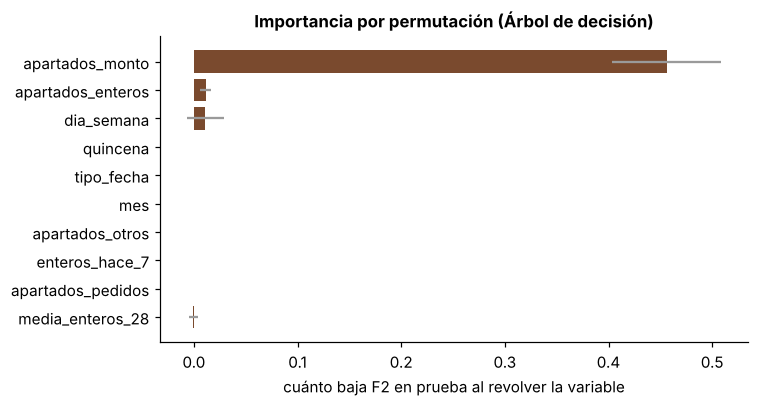

In [46]:
imp = permutation_importance(modelo, X_test, y_test, scoring=f2, n_repeats=30, random_state=SEMILLA)
importancia = pd.DataFrame({"caída de F2 al revolver": imp.importances_mean, "±": imp.importances_std}, index=X_test.columns)
importancia = importancia.sort_values("caída de F2 al revolver")
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(importancia.index, importancia["caída de F2 al revolver"], xerr=importancia["±"], color=CAFE, ecolor=GRIS)
ax.set_title(f"Importancia por permutación ({elegido})"); ax.set_xlabel("cuánto baja F2 en prueba al revolver la variable")
plt.tight_layout(); plt.savefig(FIG / "final_importancia.png", dpi=150); plt.show()

Profundidad: 3 · hojas: 7


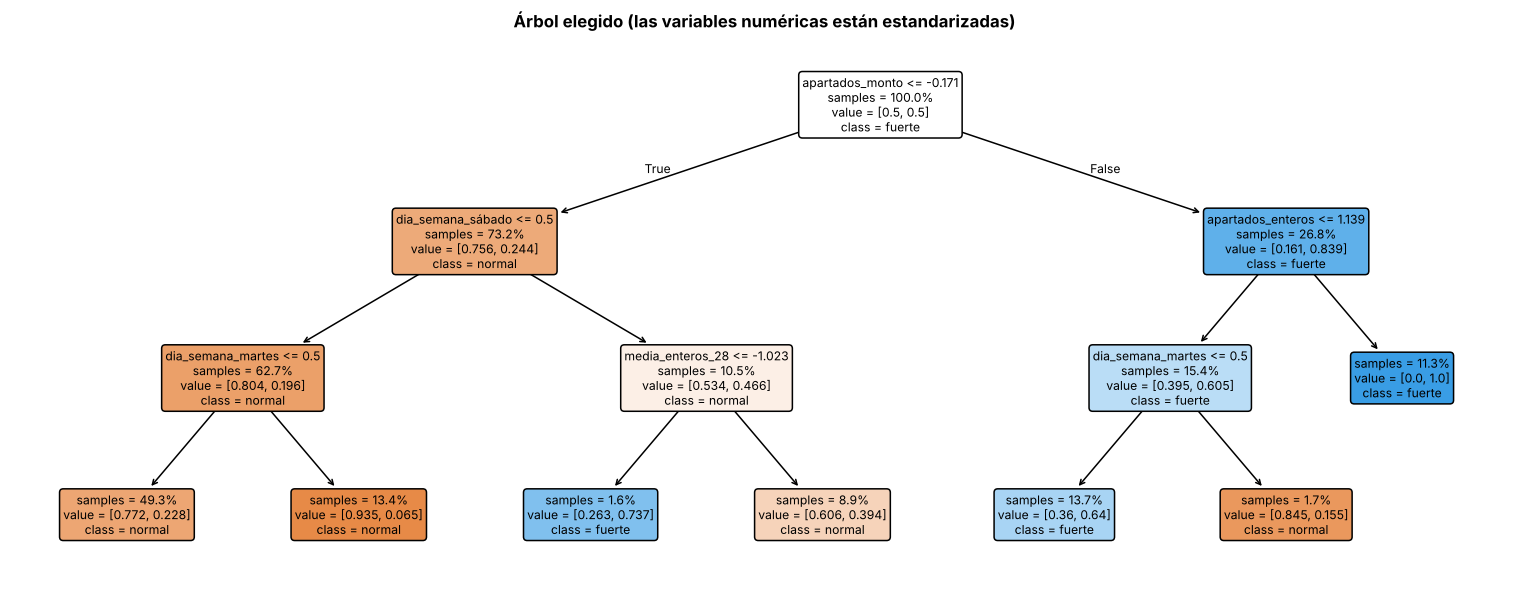

Para leer los cortes en unidades reales: valor = corte × desviación + media
                                 media  desviación
apartados_enteros                 0.45        0.92
apartados_pedidos                 0.36        0.67
apartados_monto                 215.74      444.22
apartados_otros                   0.26        1.01
enteros_hace_7                    0.77        1.15
media_enteros_28                  0.81        0.28
missingindicator_enteros_hace_7   0.06        0.23


In [47]:
if "Árbol" in elegido:
    est = modelo.named_steps["modelo"]
    print("Profundidad:", est.get_depth(), "· hojas:", est.get_n_leaves())
    nombres_t = list(modelo.named_steps["pre"].get_feature_names_out())
    plt.figure(figsize=(14, 5.5))
    plot_tree(est, feature_names=nombres_t, class_names=["normal", "fuerte"], filled=True, rounded=True,
              impurity=False, proportion=True, fontsize=8)
    plt.title("Árbol elegido (las variables numéricas están estandarizadas)")
    plt.tight_layout(); plt.savefig(FIG / "final_arbol.png", dpi=150); plt.show()
    escala = modelo.named_steps["pre"].named_transformers_["numericas"][1]
    print("Para leer los cortes en unidades reales: valor = corte × desviación + media")
    print(pd.DataFrame({"media": escala.mean_, "desviación": escala.scale_},
                       index=NUMERICAS + ["missingindicator_enteros_hace_7"]).round(2).to_string())

Leído en unidades reales (corte × desviación + media), el árbol dice:

1. ¿Hay algo apartado para ese día (más de unos 140 pesos)? Es la primera pregunta y es casi todo el modelo: revolver `apartados_monto` hace caer el F2 en 0.46, y revolver cualquier otra variable lo mueve menos de 0.02.
2. Si hay apartado y son 2 pasteles enteros o más, es día fuerte (sin excepción en el entrenamiento).
3. Si hay 1 pastel apartado, es día fuerte salvo que sea martes.
4. Si no hay nada apartado, es día normal. Solo en sábados con un promedio reciente bajo el árbol abre una rama hacia "fuerte", pero se apoya en pocos días (1.6% del entrenamiento) y en el año de prueba no se activó ni una vez; no la tomaríamos como regla de negocio.

En la figura, `value` muestra las proporciones ya ponderadas por `class_weight`, por eso la raíz aparece en 50/50 aunque en los datos hay 22% de días fuertes.

Es casi la misma regla simple de referencia, con un ajuste: un pastel apartado para miércoles o jueves también cuenta, no solo de viernes a domingo; para martes, no. La quincena, el mes, las fechas especiales y la historia de la semana anterior no aportan una vez que se sabe lo apartado, igual que se anticipaba en el EDA. Las fechas especiales sí importan, pero su efecto ya llega a través de los apartados: la gente aparta con días de anticipación para el 10 de mayo.

## 21. Predicciones del año de prueba

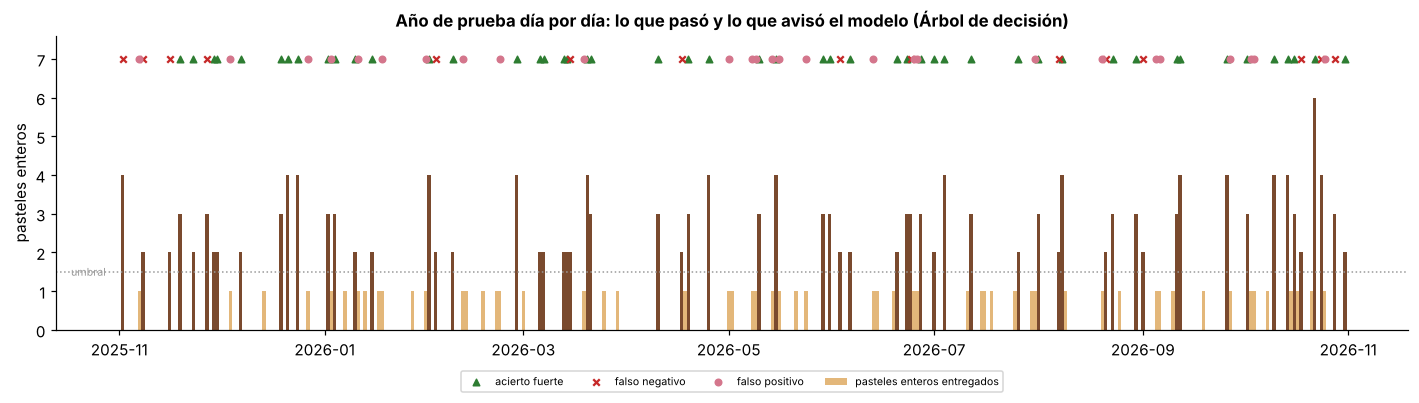

In [48]:
fig, ax = plt.subplots(figsize=(13, 3.8))
tope = res["enteros"].max() + 1
ax.bar(res.index, res["enteros"], color=np.where(res["real"] == 1, CAFE, ARENA), width=1, label="pasteles enteros entregados")
marca = {"acierto fuerte": ("^", "#2e7d32"), "falso negativo": ("x", "#c62828"), "falso positivo": ("o", ROSA)}
for k, (m, c) in marca.items():
    s = res[res["resultado"] == k]
    ax.scatter(s.index, np.full(len(s), tope), marker=m, color=c, s=18, label=k, zorder=3)
ax.axhline(1.5, color=GRIS, ls=":", lw=1)
ax.text(res.index[0] - pd.Timedelta(days=4), 1.5, "umbral", fontsize=7, color=GRIS, ha="right", va="center")
ax.set_ylim(0, tope + 0.6); ax.set_ylabel("pasteles enteros"); ax.legend(ncol=4, fontsize=7, loc="upper center", bbox_to_anchor=(.5, -.12))
ax.set_title(f"Año de prueba día por día: lo que pasó y lo que avisó el modelo ({elegido})")
plt.tight_layout(); plt.savefig(FIG / "final_predicciones.png", dpi=150); plt.show()

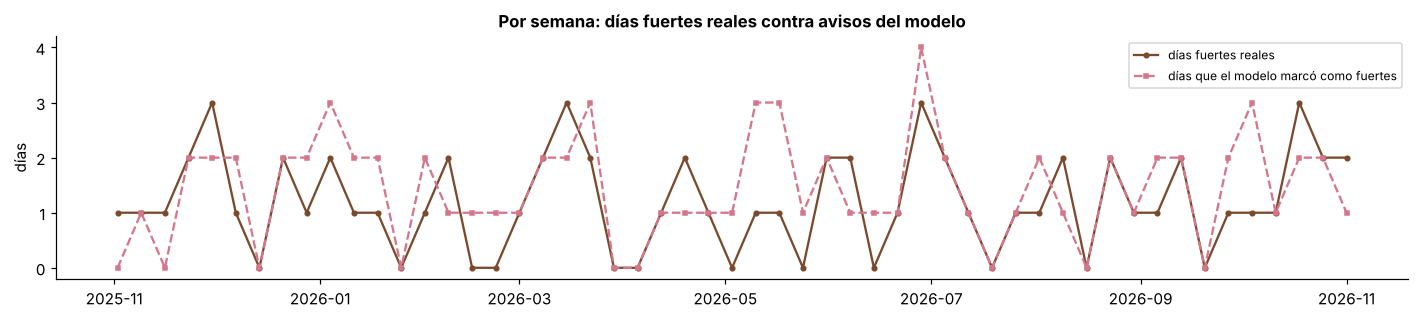

In [49]:
semanal = res.resample("W-SUN").agg({"real": "sum", "predicho": "sum"})
fig, ax = plt.subplots(figsize=(13, 3))
ax.plot(semanal.index, semanal["real"], color=CAFE, marker="o", ms=3, label="días fuertes reales")
ax.plot(semanal.index, semanal["predicho"], color=ROSA, marker="s", ms=3, ls="--", label="días que el modelo marcó como fuertes")
ax.set_title("Por semana: días fuertes reales contra avisos del modelo"); ax.legend(fontsize=8); ax.set_ylabel("días")
plt.tight_layout(); plt.show()

## 22. Guardar resultados

In [50]:
resultados = {
    "datos": {"dias": len(dias), "entrenamiento": len(X_train), "prueba": len(X_test),
              "pct_fuertes": round(float(y.mean()), 4), "variables": len(NUMERICAS + CATEGORICAS + BINARIAS)},
    "preliminar": comparativa.round(4).reset_index().to_dict("records"),
    "optimizacion": optimizacion.assign(**{"mejores hiperparámetros": optimizacion["mejores hiperparámetros"].astype(str)}).round(4).reset_index().to_dict("records"),
    "final": final.round(4).reset_index().to_dict("records"),
    "costos": costos.reset_index().to_dict("records"),
    "elegido": elegido,
    "errores": res["resultado"].value_counts().to_dict(),
    "importancia": importancia["caída de F2 al revolver"].round(4).to_dict(),
}
Path("resultados_ad.json").write_text(json.dumps(resultados, ensure_ascii=False, indent=1, default=str))
print("resultados_ad.json guardado")

resultados_ad.json guardado


## 23. Conclusión ejecutiva

Pregunta: ¿se puede saber, dos días antes, si un día va a pedir 2 o más pasteles enteros?

Respuesta: sí, en buena parte. El árbol de decisión elegido detecta 49 de los 64 días fuertes del año de prueba (recall 0.77) con 27 falsas alarmas en 296 días (precisión 0.65, F1 0.70, F2 0.74, exactitud 0.86). Los cuatro modelos optimizados quedan entre F2 0.66 (KNN) y 0.74 (SVM y árbol).

Decisiones que Salomé puede tomar con esto:

1. Regla de producción para el jueves (o dos días antes de cualquier entrega): si ya hay al menos un pastel entero apartado para ese día y no es martes, preparar una base extra de cheesecake; si ya hay dos, el día es fuerte sin duda. Seguirla habría ahorrado unos 20,000 pesos en el año de prueba contra no anticipar nada.
2. No hace falta un modelo complicado para operar. La regla simple ("un apartado de viernes a domingo o dos en cualquier día") rinde casi igual que el mejor modelo: la diferencia es de unos 100 pesos al año. El valor del modelo está en haber confirmado la regla con datos, en ajustar sus bordes (un apartado para miércoles o jueves también cuenta; para martes, no) y en dar una probabilidad que el tablero del proyecto de nube ya muestra.
3. Lo que falta para mejorar no es otro algoritmo, es otra información. 14 de los 15 días fuertes que se escaparon llegaron sin nada apartado. Dos acciones concretas: pedir a sus clientes que aparten con tres días o más (por ejemplo, con un pequeño descuento por pedido anticipado), lo que convierte días impredecibles en días con apartado; y anotar las consultas que no se cierran ("¿tienes para el sábado?"), que serían la variable que hoy no existe.

Límites: el modelo se debe volver a entrenar y evaluar cada temporada, conforme entren pedidos nuevos. Los costos de 500 pesos y 150 pesos son aproximados. El árbol se apoya casi por completo en una variable; si Salomé cambia su forma de tomar pedidos (por ejemplo, deja de aceptar apartados), hay que reentrenar.